In [0]:
import pandas as pd
import numpy as np

In [0]:
reviews = spark.table("analystlab.default.reviews_casestudy").toPandas()

display(reviews)

listing_id,review_id,date,reviewer_id
11798,330265172,2018-09-30,11863072
15383,330103585,2018-09-30,39147453
16455,329985788,2018-09-30,1125378
17919,330016899,2018-09-30,172717984
26827,329995638,2018-09-30,17542859
74561,330089224,2018-09-30,173044789
140355,330194958,2018-09-30,160093807
162163,329980859,2018-09-30,94026758
167998,329950677,2018-09-30,35388162
178188,330213008,2018-09-30,3652511


In [0]:
reviews.columns
reviews.shape

(10000, 4)

In [0]:
 reviews.columns

Index(['listing_id', 'review_id', 'date', 'reviewer_id'], dtype='object')

Inspect the Reviews dataset

In [0]:

# Count the number of records (rows)
print("Number of records:", reviews.shape[0])

# Count the number of columns
print("Number of columns:", reviews.shape[1])

# Display all column names
print("\nReviews columns:")
print(reviews.columns.tolist())

# Display the first five records
print("\nFirst five records:")
display(reviews.head())

Number of records: 10000
Number of columns: 4

Reviews columns:
['listing_id', 'review_id', 'date', 'reviewer_id']

First five records:


listing_id,review_id,date,reviewer_id
11798,330265172,2018-09-30,11863072
15383,330103585,2018-09-30,39147453
16455,329985788,2018-09-30,1125378
17919,330016899,2018-09-30,172717984
26827,329995638,2018-09-30,17542859


  STEP 2: Check primary and foreign keys in the Reviews dataset

In [0]:

# Check whether review_id contains duplicate values
print("========== REVIEW ID CHECK ==========")

print("Total review IDs:", reviews["review_id"].count())

print("Unique review IDs:", reviews["review_id"].nunique())

print("Duplicate review IDs:", reviews["review_id"].duplicated().sum())


# Check whether listing_id contains missing values
print("\n========== LISTING ID CHECK ==========")

print("Total listing IDs:", reviews["listing_id"].count())

print("Unique listing IDs:", reviews["listing_id"].nunique())

print("Missing listing IDs:", reviews["listing_id"].isna().sum())


# Check whether reviewer_id contains missing values
print("\n========== REVIEWER ID CHECK ==========")

print("Missing reviewer IDs:", reviews["reviewer_id"].isna().sum())

========== REVIEW ID CHECK ==========
Total review IDs: 10000
Unique review IDs: 10000
Duplicate review IDs: 0

========== LISTING ID CHECK ==========
Total listing IDs: 10000
Unique listing IDs: 7084
Missing listing IDs: 0

========== REVIEWER ID CHECK ==========
Missing reviewer IDs: 0


In [0]:
#Checking missing values
# Count missing values in each column
print("========== MISSING VALUES ==========")

missing_values = reviews.isnull().sum()

# Display missing values for every column
print(missing_values)

# Calculate the percentage of missing values
print("\n========== MISSING VALUE PERCENTAGES ==========")

missing_percentage = (reviews.isnull().sum() / len(reviews)) * 100

print(missing_percentage)

========== MISSING VALUES ==========
listing_id     0
review_id      0
date           0
reviewer_id    0
dtype: int64

========== MISSING VALUE PERCENTAGES ==========
listing_id     0.0
review_id      0.0
date           0.0
reviewer_id    0.0
dtype: float64


In [0]:
#Check duplicate records in the Reviews dataset

# Count all completely duplicated rows
print("========== DUPLICATE RECORD CHECK ==========")

duplicate_count = reviews.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

# Display duplicate records if any exist
print("\nDuplicate records:")

duplicates = reviews[reviews.duplicated(keep=False)]

if duplicates.empty:
    print("None found - no duplicate records in the dataset")
else:
    display(duplicates)

========== DUPLICATE RECORD CHECK ==========
Number of duplicate records: 0

Duplicate records:
None found - no duplicate records in the dataset


In [0]:
# Inspect data types in the Reviews dataset

# Display the data type of each column
print("========== DATA TYPES ==========")

print(reviews.dtypes)

# Display additional information about the dataset
print("\n========== DATASET INFORMATION ==========")

reviews.info()

========== DATA TYPES ==========
listing_id      int64
review_id       int64
date           object
reviewer_id     int64
dtype: object

========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   listing_id   10000 non-null  int64 
 1   review_id    10000 non-null  int64 
 2   date         10000 non-null  object
 3   reviewer_id  10000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 312.6+ KB


In [0]:
 # STEP 5: Inspect data types in the Reviews dataset
# Display the data type of each column
print("========== DATA TYPES ==========")

print(reviews.dtypes)

# Display additional information about the dataset
print("\n========== DATASET INFORMATION ==========")

reviews.info()

========== DATA TYPES ==========
listing_id      int64
review_id       int64
date           object
reviewer_id     int64
dtype: object

========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   listing_id   10000 non-null  int64 
 1   review_id    10000 non-null  int64 
 2   date         10000 non-null  object
 3   reviewer_id  10000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 312.6+ KB


In [0]:
 # Import pandas
import pandas as pd

# Convert the date column into datetime format
reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce")

# Display the updated data types
print("========== UPDATED DATA TYPES ==========")
print(reviews.dtypes)

# Check whether any dates failed to convert
print("\nInvalid or missing dates:", reviews["date"].isna().sum())

# Display the first five converted dates
display(reviews[["date"]].head())

========== UPDATED DATA TYPES ==========
listing_id              int64
review_id               int64
date           datetime64[ns]
reviewer_id             int64
dtype: object

Invalid or missing dates: 0


date
2018-09-30T00:00:00.000Z
2018-09-30T00:00:00.000Z
2018-09-30T00:00:00.000Z
2018-09-30T00:00:00.000Z
2018-09-30T00:00:00.000Z


In [0]:
 # Extract date components from the review date
# Extract the year from each review date
reviews["date"] = pd.to_datetime(reviews["date"])
reviews["year"] = reviews["date"].dt.year

# Extract the month number (1–12)
reviews["month"] = reviews["date"].dt.month

# Extract the month name (January, February, etc.)
reviews["month_name"] = reviews["date"].dt.month_name()

# Extract the day of the month
reviews["day"] = reviews["date"].dt.day

# Extract the day of the week (Monday, Tuesday, etc.)
reviews["day_name"] = reviews["date"].dt.day_name()

# Display the original date and newly extracted columns
display(
    reviews[
        ["date", "year", "month", "month_name", "day", "day_name"]
    ].head(10)
)

date,year,month,month_name,day,day_name
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday
2018-09-30T00:00:00.000Z,2018,9,September,30,Sunday


In [0]:
 # Find the earliest review date
print("Earliest review date:", reviews["date"].min())

# Find the latest review date
print("Latest review date:", reviews["date"].max())

# Count the number of different years
print("Years covered:", reviews["year"].nunique())

Earliest review date: 2018-06-03 00:00:00
Latest review date: 2019-06-02 00:00:00
Years covered: 2


In [0]:
 #Inspect the unique values in the Reviews dataset

# Check the number of unique listings
print("Unique listings:", reviews["listing_id"].nunique())

# Check the number of unique reviewers
print("Unique reviewers:", reviews["reviewer_id"].nunique())

# Check the years represented
print("\nYears:")
print(sorted(reviews["year"].unique()))

# Check the months represented
print("\nMonths:")
print(sorted(reviews["month"].unique()))

# Check the days of the week represented
print("\nDays of the week:")
print(reviews["day_name"].value_counts())

Unique listings: 7084
Unique reviewers: 9982

Years:
[np.int32(2018), np.int32(2019)]

Months:
[np.int32(1), np.int32(4), np.int32(6), np.int32(9), np.int32(11)]

Days of the week:
day_name
Sunday     6805
Monday     1604
Tuesday    1591
Name: count, dtype: int64


In [0]:
#Count reviews by year and month
# Group the reviews by year and month name
monthly_reviews = (
    reviews.groupby(["year", "month_name"])
    .size()
    .reset_index(name="total_reviews")
)

# Sort the results chronologically
monthly_reviews = monthly_reviews.sort_values(
    by=["year", "month"]
    if "month" in monthly_reviews.columns
    else ["year", "month_name"]
)

# Display the results
print("========== REVIEWS BY YEAR AND MONTH ==========")
display(monthly_reviews)

========== REVIEWS BY YEAR AND MONTH ==========


year,month_name,total_reviews
2018,June,1336
2018,November,2009
2018,September,1566
2019,April,1604
2019,January,1591
2019,June,1894


In [0]:
 # Check whether Reviews listing IDs match Listings listing IDs

# Load the Listings dataset
listing = spark.table("analystlab.default.listing_casestudy").toPandas()

# Get the unique listing IDs from the Listings dataset
listing_ids = listing["listing_id"].unique()

# Get the unique listing IDs from the Reviews dataset
review_listing_ids = reviews["listing_id"].unique()

# Find review listing IDs that do not exist in Listings
unmatched_ids = set(review_listing_ids) - set(listing_ids)

# Display the results
print("========== LISTING-REVIEW RELATIONSHIP ==========")

print("Unique listing IDs in Reviews:", len(review_listing_ids))

print("Unique listing IDs in Listings:", len(listing_ids))

print("Unmatched listing IDs:", len(unmatched_ids))

# Display unmatched IDs if any exist
print("Unmatched IDs:", list(unmatched_ids)[:10])

========== LISTING-REVIEW RELATIONSHIP ==========
Unique listing IDs in Reviews: 7084
Unique listing IDs in Listings: 2953
Unmatched listing IDs: 7042
Unmatched IDs: [np.int64(20414473), np.int64(26771469), np.int64(13074447), np.int64(28377107), np.int64(4194324), np.int64(18907157), np.int64(5767189), np.int64(6324247), np.int64(8323096), np.int64(4259868)]


In [0]:

# Calculate matching and unmatched listing IDs
# Find listing IDs that exist in both datasets
matched_ids = set(review_listing_ids).intersection(set(listing_ids))

# Calculate the number of matching IDs
print("Matching listing IDs:", len(matched_ids))

# Calculate the matching percentage
matching_percentage = (
    len(matched_ids) / len(review_listing_ids)
) * 100

print("Matching percentage:", round(matching_percentage, 2), "%")

# Calculate the unmatched percentage
unmatched_percentage = (
    len(unmatched_ids) / len(review_listing_ids)
) * 100

print("Unmatched percentage:", round(unmatched_percentage, 2), "%")

Matching listing IDs: 42
Matching percentage: 0.59 %
Unmatched percentage: 99.41 %


In [0]:
 # Compare listing ID ranges and samples

# Inspect the first 10 listing IDs in the Listings dataset
print("========== LISTINGS ID SAMPLE ==========")
print(listing["listing_id"].head(10).tolist())

# Inspect the first 10 listing IDs in the Reviews dataset
print("\n========== REVIEWS ID SAMPLE ==========")
print(reviews["listing_id"].head(10).tolist())

# Compare the minimum and maximum listing IDs
print("\n========== LISTING ID RANGES ==========")

print("Listings minimum ID:", listing["listing_id"].min())
print("Listings maximum ID:", listing["listing_id"].max())

print("Reviews minimum ID:", reviews["listing_id"].min())
print("Reviews maximum ID:", reviews["listing_id"].max())

# Check how many records are in the Listings dataset
print("\nListings records:", len(listing))

# Check the cities represented in Listings, if available
if "city" in listing.columns:
    print("\n========== LISTINGS BY CITY ==========")
    print(listing["city"].value_counts(dropna=False))

========== LISTINGS ID SAMPLE ==========
[22739162, 23329589, 23549493, 28682925, 29495694, 29630526, 30254934, 30401949, 31762273, 32679231]

========== REVIEWS ID SAMPLE ==========
[11798, 15383, 16455, 17919, 26827, 74561, 140355, 162163, 167998, 178188]

========== LISTING ID RANGES ==========
Listings minimum ID: 8490
Listings maximum ID: 48280345
Reviews minimum ID: 11170
Reviews maximum ID: 30741253

Listings records: 2953

========== LISTINGS BY CITY ==========
city
Cape Town         513
Sydney            484
Mexico City       430
Istanbul          323
Rome              310
Rio de Janeiro    276
Bangkok           235
Paris             196
New York          122
Hong Kong          60
null                4
Name: count, dtype: int64


In [0]:
 #Identify the cities of matching listings

# Filter Listings to include only IDs found in Reviews
matched_listings = listing[
    listing["listing_id"].isin(review_listing_ids)
]

# Count matching listings by city
print("========== MATCHED LISTINGS BY CITY ==========")

print(matched_listings["city"].value_counts())

# Display the matching listing records
print("\nMatching listing records:")

display(
    matched_listings[
        ["listing_id", "name", "city", "room_type", "price"]
    ]
)

========== MATCHED LISTINGS BY CITY ==========
city
Paris    42
Name: count, dtype: int64

Matching listing records:


listing_id,name,city,room_type,price
11439491,2 piÃ¨ces de charme a Aligre.,Paris,Entire place,78
17989442,NICE BED+BREAKFAST PARIS 15 near EIFFEL TOWER,Paris,Private room,79
23477794,Loft apartment in the heart of Paris,Paris,Entire place,120
28663096,T2 ideal pour touristes,Paris,Entire place,70
29769710,Loft convivial proche Montmartre,Paris,Entire place,55
27617280,Appartement type loft 60m^2 au coeur de Paris,Paris,Entire place,75
22894103,Artist's studio converted into charming apartment,Paris,Entire place,80
26532242,studio au 1er etage avec une grande terrasse,Paris,Entire place,70
19125827,Hip loft in the heart of Paris,Paris,Entire place,159
21180585,Chambre avec vue sur Sacre-Coeur,Paris,Private room,40


In [0]:
 # STEP 9.4: Recheck all cities in the Listings dataset

# Display the unique city names
print("========== UNIQUE CITIES ==========")
print(sorted(listing["city"].dropna().unique()))

# Count listings in every city
print("\n========== COMPLETE CITY DISTRIBUTION ==========")
print(listing["city"].value_counts(dropna=False))

# Count the number of matching listings by city
print("\n========== MATCHING LISTINGS BY CITY ==========")
print(matched_listings["city"].value_counts(dropna=False))

========== UNIQUE CITIES ==========
['Bangkok', 'Cape Town', 'Hong Kong', 'Istanbul', 'Mexico City', 'New York', 'Paris', 'Rio de Janeiro', 'Rome', 'Sydney', 'null']

========== COMPLETE CITY DISTRIBUTION ==========
city
Cape Town         513
Sydney            484
Mexico City       430
Istanbul          323
Rome              310
Rio de Janeiro    276
Bangkok           235
Paris             196
New York          122
Hong Kong          60
null                4
Name: count, dtype: int64

========== MATCHING LISTINGS BY CITY ==========
city
Paris    42
Name: count, dtype: int64


In [0]:
 # STEP 10: Investigate review dates by day of the week

# Count the number of reviews for each weekday
weekday_counts = (
    reviews.groupby("day_name")
    .size()
    .reset_index(name="total_reviews")
)

# Display weekdays in calendar order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_counts["day_name"] = pd.Categorical(
    weekday_counts["day_name"],
    categories=weekday_order,
    ordered=True
)

weekday_counts = weekday_counts.sort_values("day_name")

# Display the results
print("========== REVIEW DISTRIBUTION BY WEEKDAY ==========")
display(weekday_counts)

# Display the first 15 dates for verification
print("\n========== SAMPLE REVIEW DATES ==========")
display(reviews[["date", "day_name"]].head(15))

========== REVIEW DISTRIBUTION BY WEEKDAY ==========


day_name,total_reviews
Monday,1604
Tuesday,1591
Sunday,6805



========== SAMPLE REVIEW DATES ==========


date,day_name
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday
2018-09-30T00:00:00.000Z,Sunday


In [0]:
 # STEP 11: Check date validity and consistency

# Check for missing dates
print("Missing dates:", reviews["date"].isna().sum())

# Check for dates outside the expected period
print(
    "Dates before June 2018:",
    (reviews["date"] < "2018-06-01").sum()
)

print(
    "Dates after June 2019:",
    (reviews["date"] > "2019-06-30").sum()
)

# Check whether the extracted year matches the original date
print(
    "Year mismatches:",
    (reviews["year"] != reviews["date"].dt.year).sum()
)

# Check whether the extracted month matches the original date
print(
    "Month mismatches:",
    (reviews["month"] != reviews["date"].dt.month).sum()
)

Missing dates: 0
Dates before June 2018: 0
Dates after June 2019: 0
Year mismatches: 0
Month mismatches: 0


Analyse review activity by listing and over time

In [0]:
 
# STEP 1: Count the number of reviews for each listing
# Group reviews by listing_id.
# Count how many review records belong to each listing.
reviews_per_listing = (
    reviews.groupby("listing_id")
    .agg(
        total_reviews=("review_id", "count")
    )
    .reset_index()
)

# Sort listings from the highest number of reviews to the lowest.
reviews_per_listing = reviews_per_listing.sort_values(
    by="total_reviews",
    ascending=False
)

# Display the 10 listings with the most reviews.
print("TOP 10 LISTINGS BY NUMBER OF REVIEWS")

display(reviews_per_listing.head(10))


# STEP 2: Calculate summary statistics

print("REVIEW ACTIVITY SUMMARY")

print(reviews_per_listing["total_reviews"].describe())


# STEP 3: Count how many listings have different review counts

print("DISTRIBUTION OF REVIEWS PER LISTING")

print(reviews_per_listing["total_reviews"].value_counts().sort_index())


TOP 10 LISTINGS BY NUMBER OF REVIEWS


listing_id,total_reviews
18305959,8
18299179,7
6510110,6
18609786,6
20806949,6
29348181,5
28355862,5
22398638,5
18411135,5
24030305,5


REVIEW ACTIVITY SUMMARY
count    7084.000000
mean        1.411632
std         0.703321
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         8.000000
Name: total_reviews, dtype: float64
DISTRIBUTION OF REVIEWS PER LISTING
total_reviews
1    4878
2    1639
3     453
4      93
5      16
6       3
7       1
8       1
Name: count, dtype: int64


In [0]:
 
# STEP 1: Group reviews by year and month
# Count the number of reviews recorded in each month.
monthly_reviews = (
    reviews.groupby(["year", "month"])
    .agg(
        total_reviews=("review_id", "count")
    )
    .reset_index()
)

# Sort the results chronologically.
monthly_reviews = monthly_reviews.sort_values(
    by=["year", "month"]
)

# Display the monthly review counts.
print("MONTHLY REVIEW ACTIVITY")

display(monthly_reviews)


# STEP 2: Create a year-month column for easier plotting
# Convert the year and month into a date format.
monthly_reviews["year_month"] = pd.to_datetime(
    monthly_reviews["year"].astype(str)
    + "-"
    + monthly_reviews["month"].astype(str)
    + "-01"
)

# Display the final results.
display(monthly_reviews)


MONTHLY REVIEW ACTIVITY


year,month,total_reviews
2018,6,1336
2018,9,1566
2018,11,2009
2019,1,1591
2019,4,1604
2019,6,1894


year,month,total_reviews,year_month
2018,6,1336,2018-06-01T00:00:00.000Z
2018,9,1566,2018-09-01T00:00:00.000Z
2018,11,2009,2018-11-01T00:00:00.000Z
2019,1,1591,2019-01-01T00:00:00.000Z
2019,4,1604,2019-04-01T00:00:00.000Z
2019,6,1894,2019-06-01T00:00:00.000Z


### Review Activity Over Time

The monthly review analysis examined the number of reviews recorded across the available months between June 2018 and June 2019.

The results showed six year-month combinations. June 2018 recorded 1,336 reviews, September 2018 recorded 1,566, and November 2018 recorded the highest activity, with 2,009 reviews. In 2019, January recorded 1,591 reviews, April recorded 1,604, and June recorded 1,894.

The findings demonstrate that the number of recorded reviews varied across the available months. November 2018 had the highest review count, while June 2018 had the lowest.

However, the dataset does not contain continuous monthly observations. Therefore, the results cannot establish a consistent long-term trend or confirm seasonal patterns in Airbnb review activity. The findings describe only the months represented in the supplied sample.

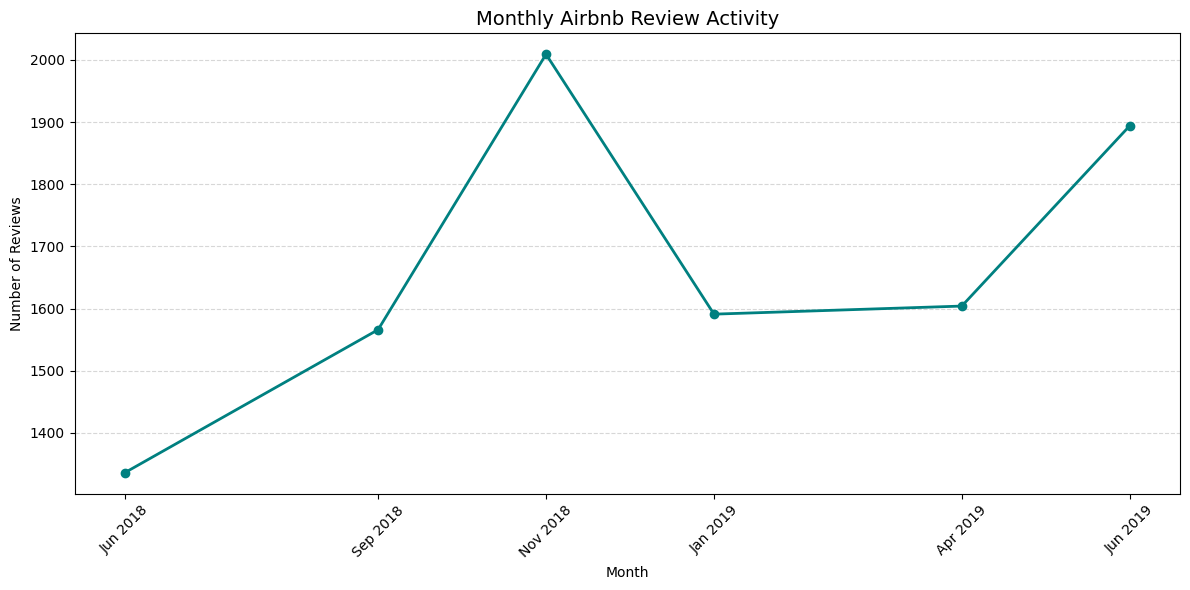

In [0]:
 
# Import Matplotlib for creating the graph.
import matplotlib.pyplot as plt

# Create a figure with a suitable size.
plt.figure(figsize=(12, 6))

# Plot monthly review activity.
plt.plot(
    monthly_reviews["year_month"],
    monthly_reviews["total_reviews"],
    marker="o",
    linewidth=2,
    color="teal"
)

# Add a title and axis labels.
plt.title("Monthly Airbnb Review Activity", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Number of Reviews")

# Display each available month on the x-axis.
plt.xticks(
    monthly_reviews["year_month"],
    monthly_reviews["year_month"].dt.strftime("%b %Y"),
    rotation=45
)

# Add gridlines to make values easier to read.
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()


In [0]:
 
# STEP 1: Inspect the bedrooms and price columns

# Display the data types of both columns.
print("DATA TYPES")
print(listing[["bedrooms", "price"]].dtypes)

# Display the first 10 values to check their format.
print("\nSAMPLE VALUES")
display(listing[["bedrooms", "price"]].head(10))

# Check how many missing values each column contains.
print("\nMISSING VALUES")
print(listing[["bedrooms", "price"]].isna().sum())


DATA TYPES
bedrooms    object
price       object
dtype: object

SAMPLE VALUES


bedrooms,price
1,30
1,395
1,72
1,20
1,50
1,150
1,59
1,120
1,40
1,29



MISSING VALUES
bedrooms    0
price       0
dtype: int64


- 2,949 valid records for both bedrooms and price.
- 4 missing values in each column.
- Average bedrooms: approximately 1.00.
- Average advertised price: approximately 420.61.
- Maximum advertised price: 8,097.

In [0]:
 
# Convert bedrooms to numeric values.
# Invalid values will become NaN (missing values).
listing["bedrooms"] = pd.to_numeric(
    listing["bedrooms"],
    errors="coerce"
)

# Remove currency symbols and commas from price, if present.
listing["price"] = (
    listing["price"]
    .astype(str)
    .str.replace(r"[$,]", "", regex=True)
)

# Convert price into numeric values.
listing["price"] = pd.to_numeric(
    listing["price"],
    errors="coerce"
)

# Check the updated data types.
print("UPDATED DATA TYPES")
print(listing[["bedrooms", "price"]].dtypes)

# Check missing values after conversion.
print("\nMISSING VALUES")
print(listing[["bedrooms", "price"]].isna().sum())

# Display summary statistics.
print("\nSUMMARY STATISTICS")
display(listing[["bedrooms", "price"]].describe())


UPDATED DATA TYPES
bedrooms    float64
price       float64
dtype: object

MISSING VALUES
bedrooms    4
price       4
dtype: int64

SUMMARY STATISTICS


bedrooms,price
2949.0,2949.0
1.0,420.6127500847745
0.0,555.174915827779
1.0,9.0
1.0,81.0
1.0,229.0
1.0,585.0
1.0,8097.0


Calculate the correlation

In [0]:
 
# Select records that have both bedrooms and price available.
bedroom_price = listing[
    ["bedrooms", "price"]
].dropna().copy()

# Calculate Pearson correlation.
correlation = bedroom_price["bedrooms"].corr(
    bedroom_price["price"],
    method="pearson"
)

# Display the result.
print("CORRELATION BETWEEN BEDROOMS AND PRICE")
print("Pearson correlation:", correlation)

# Interpret the strength and direction.
if correlation > 0:
    print("The relationship is positive.")
elif correlation < 0:
    print("The relationship is negative.")
else:
    print("There is no linear relationship.")


CORRELATION BETWEEN BEDROOMS AND PRICE
Pearson correlation: nan
There is no linear relationship.


/databricks/python/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/databricks/python/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [0]:
 
# Check how many different bedroom values exist.
print("UNIQUE BEDROOM VALUES:")
print(listing["bedrooms"].value_counts().sort_index())

# Check how many different prices exist.
print("\nNUMBER OF UNIQUE PRICES:")
print(listing["price"].nunique())

# Check the standard deviation of both columns.
print("\nSTANDARD DEVIATION:")
print(listing[["bedrooms", "price"]].std())

# Check whether either column has only one unique value.
print("\nUNIQUE VALUE COUNTS:")
print("Bedrooms:", listing["bedrooms"].nunique())
print("Price:", listing["price"].nunique())


UNIQUE BEDROOM VALUES:
bedrooms
1.0    2949
Name: count, dtype: int64

NUMBER OF UNIQUE PRICES:
711

STANDARD DEVIATION:
bedrooms      0.000000
price       555.174916
dtype: float64

UNIQUE VALUE COUNTS:
Bedrooms: 1
Price: 711


In [0]:
 
# Check the data types of accommodation capacity and price.
print("DATA TYPES")
print(listing[["accommodates", "price"]].dtypes)

# Display the different accommodation capacities.
print("\nACCOMMODATION CAPACITY")
print(listing["accommodates"].value_counts().sort_index())

# Check how many unique accommodation capacities exist.
print("\nUNIQUE CAPACITIES")
print(listing["accommodates"].nunique())


DATA TYPES
accommodates     object
price           float64
dtype: object

ACCOMMODATION CAPACITY
accommodates
1        305
10         2
16         5
2       1791
3        369
4        395
5         44
6         29
7          1
8          8
null       4
Name: count, dtype: int64

UNIQUE CAPACITIES
11


In [0]:
 # Convert accommodation capacity to numbers.
# Any text values such as "null" will become missing values (NaN).
listing["accommodates"] = pd.to_numeric(
    listing["accommodates"],
    errors="coerce"
)

# Check the updated data type.
print("DATA TYPE:")
print(listing["accommodates"].dtype)

# Count missing values after conversion.
print("\nMISSING VALUES:")
print(listing["accommodates"].isna().sum())

# Display the accommodation capacity distribution.
print("\nACCOMMODATION CAPACITY:")
print(listing["accommodates"].value_counts().sort_index())

DATA TYPE:
float64

MISSING VALUES:
4

ACCOMMODATION CAPACITY:
accommodates
1.0      305
2.0     1791
3.0      369
4.0      395
5.0       44
6.0       29
7.0        1
8.0        8
10.0       2
16.0       5
Name: count, dtype: int64


Calculate the correlation between capacity and price

In [0]:
 # Select accommodates and price, removing rows with missing values.
capacity_price = listing[["accommodates", "price"]].dropna().copy()

# Calculate the Pearson correlation.
correlation = capacity_price["accommodates"].corr(
    capacity_price["price"],
    method="pearson"
)

# Display the result.
print("Pearson correlation:", correlation)

Pearson correlation: 0.013097581021637609


Visualise accommodation capacity and price

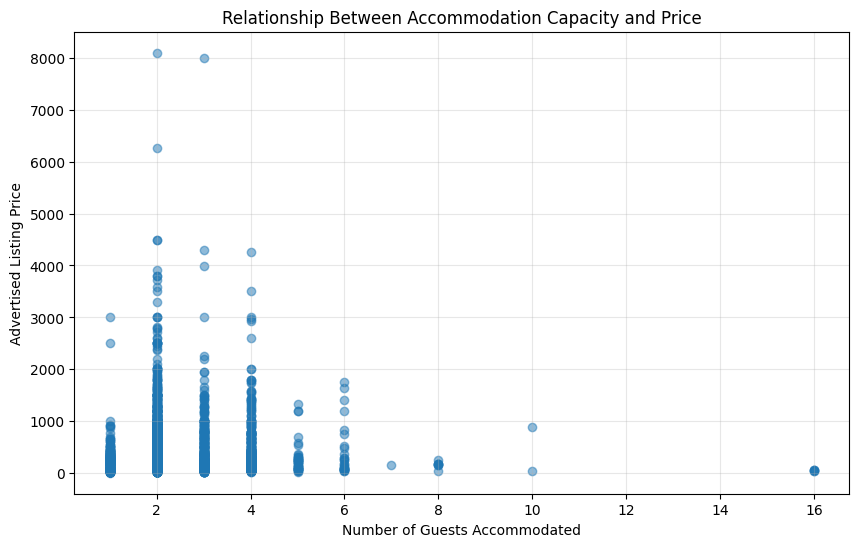

In [0]:
import matplotlib.pyplot as plt

# Create a scatter plot.
plt.figure(figsize=(10, 6))

plt.scatter(
    capacity_price["accommodates"],
    capacity_price["price"],
    alpha=0.5
)

# Add chart labels and title.
plt.title("Relationship Between Accommodation Capacity and Price")
plt.xlabel("Number of Guests Accommodated")
plt.ylabel("Advertised Listing Price")

# Display the chart.
plt.grid(True, alpha=0.3)
plt.show()

In [0]:
 # Check the available room types.
print("ROOM TYPES")
print(listing["room_type"].value_counts())

# Check missing values in room type and price.
print("\nMISSING VALUES")
print(listing[["room_type", "price"]].isna().sum())

ROOM TYPES
room_type
Private room    1483
Entire place    1286
Hotel room        94
Shared room       86
null               4
Name: count, dtype: int64

MISSING VALUES
room_type    0
price        4
dtype: int64


Key findings:
1. Entire places have the highest average advertised price (532.62).
2. Hotel rooms have the second-highest average (442.84).
3. Private rooms have an average price of 334.98.
4. Shared rooms have the lowest average price (198.09).
The median prices are lower than the averages for all four categories. This suggests that some higher-priced listings are pulling the averages upwards.

Important limitation: These listings cover different cities and countries. The price differences may reflect local currency, location and market conditions, not room type alone.

In [0]:
 # Keep only valid room types and prices.
room_price = listing[
    (listing["room_type"] != "null") &
    (listing["price"].notna())
].copy()

# Group listings by room type and calculate price statistics.
room_price_summary = (
    room_price.groupby("room_type")
    .agg(
        total_listings=("price", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        minimum_price=("price", "min"),
        maximum_price=("price", "max")
    )
    .round(2)
    .sort_values(by="average_price", ascending=False)
)


display(room_price_summary)

total_listings,average_price,median_price,minimum_price,maximum_price
1286,532.62,327.5,25.0,8097.0
94,442.84,296.0,24.0,4500.0
1483,334.98,173.0,15.0,4500.0
86,198.09,83.5,9.0,1990.0


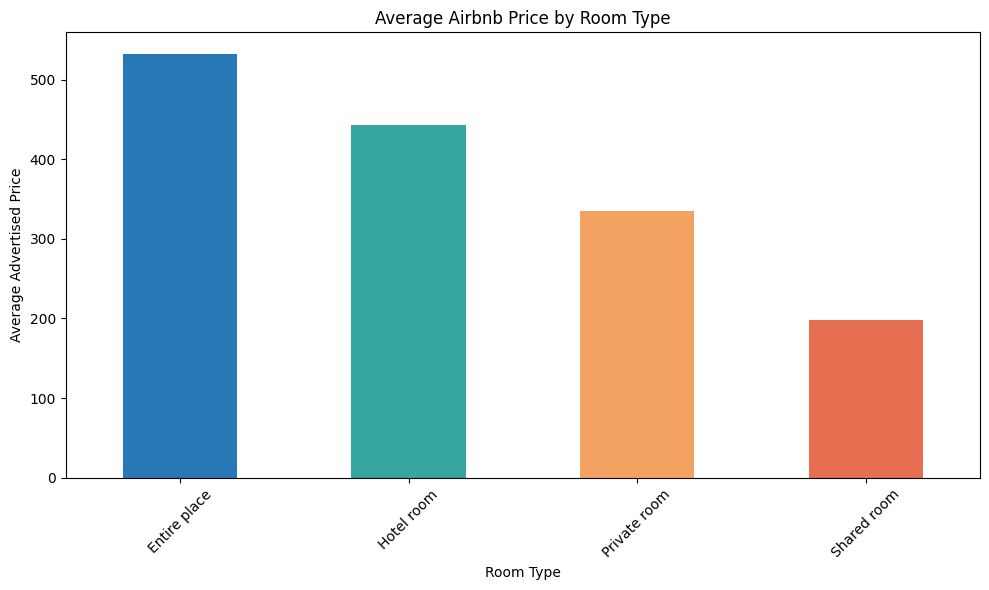

In [0]:
import matplotlib.pyplot as plt

# Get the average price for each room type.
average_prices = room_price_summary["average_price"].sort_values(
    ascending=False
)

# Create the bar chart.
plt.figure(figsize=(10, 6))

average_prices.plot(
    kind="bar",
    color=["#2878B5", "#35A7A0", "#F4A261", "#E76F51"]
)

# Add chart title and labels.
plt.title("Average Airbnb Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Average Advertised Price")

# Rotate category labels for readability.
plt.xticks(rotation=45)

# Display the chart.
plt.tight_layout()
plt.show()

Inspect property types

In [0]:
 # Display the number of listings in each property type.
print("PROPERTY TYPES")
print(listing["property_type"].value_counts().head(20))

# Check missing values.
print("\nMISSING VALUES")
print(listing[["property_type", "price"]].isna().sum())

# Count the number of unique property types.
print("\nUNIQUE PROPERTY TYPES")
print(listing["property_type"].nunique())

PROPERTY TYPES
property_type
Private room in house                 710
Entire condominium                    329
Entire loft                           249
Entire guest suite                    179
Private room in condominium           172
Entire house                          155
Entire serviced apartment             143
Private room in townhouse             109
Private room in bed and breakfast      98
Private room in guest suite            97
Room in boutique hotel                 96
Entire guesthouse                      90
Shared room in apartment               45
Private room in hostel                 38
Room in aparthotel                     37
Private room in loft                   37
Entire townhouse                       36
Private room in guesthouse             33
Private room in serviced apartment     31
Room in bed and breakfast              31
Name: count, dtype: int64

MISSING VALUES
property_type    0
price            4
dtype: int64

UNIQUE PROPERTY TYPES
64


**Calculate average and median prices**

In [0]:
 # Select listings with valid property types and prices.
property_price = listing[
    (listing["property_type"] != "null") &
    (listing["price"].notna())
].copy()

# Identify the 10 most common property types.
top_10_types = property_price["property_type"].value_counts().head(10).index

# Keep only those 10 property types.
top_10_data = property_price[
    property_price["property_type"].isin(top_10_types)
]

# Calculate price statistics for each property type.
property_summary = (
    top_10_data.groupby("property_type")
    .agg(
        total_listings=("price", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median")
    )
    .round(2)
    .sort_values(by="average_price", ascending=False)
)


display(property_summary)

total_listings,average_price,median_price
329,662.44,519.0
179,542.84,466.0
249,542.16,321.0
143,503.45,318.0
97,450.16,400.0
172,432.9,179.5
155,358.05,190.0
710,306.23,190.0
98,240.32,65.0
109,210.22,87.0


The analysis indicates that entire condominiums recorded the highest average advertised price among the ten most common property types, while private rooms in townhouses recorded the lowest. Entire-property categories generally showed higher average advertised prices than several private-room categories. However, these differences should be interpreted cautiously because the dataset covers multiple cities and countries, and local market and currency differences may influence the results.

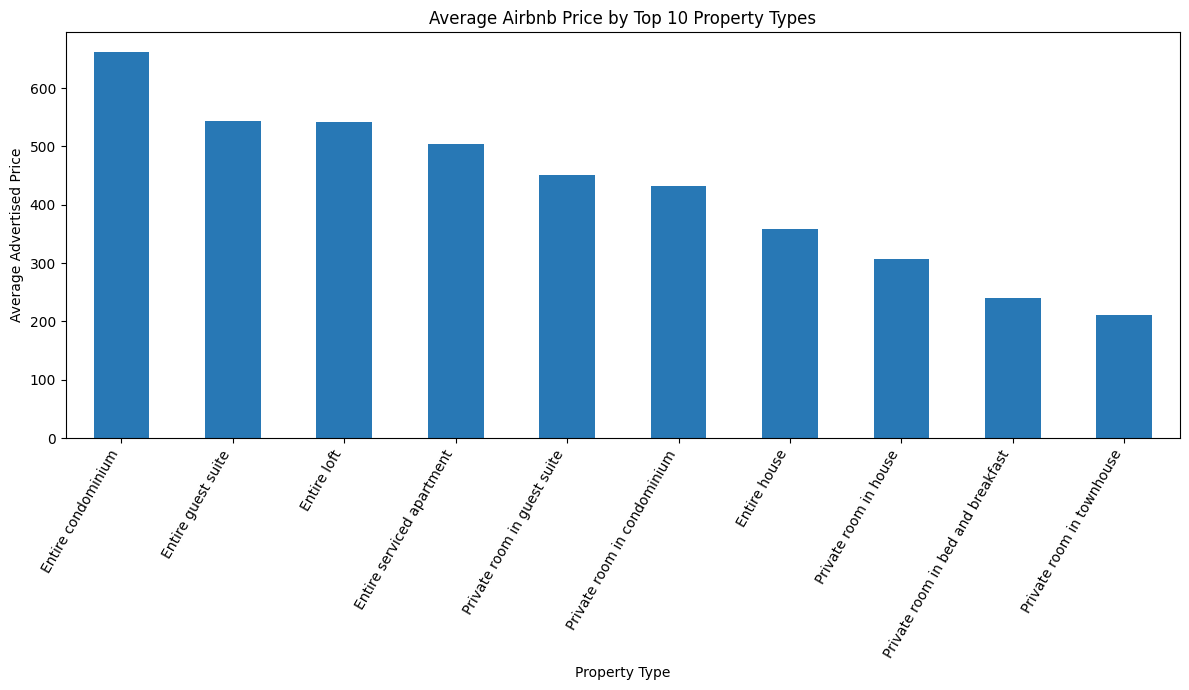

In [0]:
import matplotlib.pyplot as plt

# Sort property types by average price.
property_chart = property_summary.sort_values(
    by="average_price",
    ascending=False
)

# Create the bar chart.
plt.figure(figsize=(12, 7))

property_chart["average_price"].plot(
    kind="bar",
    color="#2878B5"
)

# Add chart title and labels.
plt.title("Average Airbnb Price by Top 10 Property Types")
plt.xlabel("Property Type")
plt.ylabel("Average Advertised Price")

# Rotate labels for readability.
plt.xticks(rotation=60, ha="right")

# Improve chart spacing.
plt.tight_layout()
plt.show()

In [0]:
 # Check whether the review rating column exists.
print("REVIEW RATING DATA TYPE")
print(listing["review_scores_rating"].dtype)

# Display the first 10 ratings.
print("\nSAMPLE RATINGS")
display(listing[["room_type", "review_scores_rating"]].head(10))

# Check missing values.
print("\nMISSING VALUES")
print(listing[["room_type", "review_scores_rating"]].isna().sum())

# Display summary statistics.
print("\nRATING SUMMARY")
print(listing.describe())

REVIEW RATING DATA TYPE
object

SAMPLE RATINGS


room_type,review_scores_rating
Shared room,98
Entire place,98
Private room,null
Shared room,100
Private room,100
Entire place,90
Entire place,100
Entire place,100
Private room,90
Private room,100



MISSING VALUES
room_type               0
review_scores_rating    0
dtype: int64

RATING SUMMARY
         listing_id  accommodates  bedrooms        price
count  2.953000e+03   2949.000000    2949.0  2949.000000
mean   2.621906e+07      2.420821       1.0   420.612750
std    1.363236e+07      1.166697       0.0   555.174916
min    8.490000e+03      1.000000       1.0     9.000000
25%    1.525588e+07      2.000000       1.0    81.000000
50%    2.623442e+07      2.000000       1.0   229.000000
75%    3.892527e+07      3.000000       1.0   585.000000
max    4.828034e+07     16.000000       1.0  8097.000000


i see my sample ratings, but there is an important issue we need to fix before calculating averages.

The review_scores_rating values appear to be numeric scores such as 98, 90 and 100, but one value is "null". The summary output also seems to show the wrong columns (listing_id, accommodates, bedrooms, and price) rather than the rating column.

This may be because the rating column is stored as text.

In [0]:
 # Replace the text "null" with a proper missing value.
listing["review_scores_rating"] = (
    listing["review_scores_rating"]
    .replace("null", pd.NA)
)

# Convert review ratings to numeric values.
listing["review_scores_rating"] = pd.to_numeric(
    listing["review_scores_rating"],
    errors="coerce"
)

# Check the data type.
print("DATA TYPE:")
print(listing["review_scores_rating"].dtype)

# Check missing ratings.
print("\nMISSING RATINGS:")
print(listing["review_scores_rating"].isna().sum())

# Display rating statistics.
print("\nRATING SUMMARY:")
print(listing["review_scores_rating"].describe())

DATA TYPE:
float64

MISSING RATINGS:
669

RATING SUMMARY:
count    2284.000000
mean       94.608581
std         8.415775
min        20.000000
25%        93.000000
50%        97.000000
75%       100.000000
max       100.000000
Name: review_scores_rating, dtype: float64


In [0]:
 # Remove listings without a valid room type or review rating.
rating_data = listing[
    (listing["room_type"] != "null") &
    (listing["review_scores_rating"].notna())
].copy()

# Group the data by room type.
rating_summary = (
    rating_data.groupby("room_type")
    .agg(
        total_listings=("review_scores_rating", "count"),
        average_rating=("review_scores_rating", "mean"),
        median_rating=("review_scores_rating", "median")
    )
    .round(2)
    .sort_values(by="average_rating", ascending=False)
)

# Display the results.
display(rating_summary)

total_listings,average_rating,median_rating
44,95.41,100.0
1084,95.1,97.0
1083,94.25,97.0
73,92.21,95.0


Key findings:
1. Hotel rooms have the highest average rating (95.41).
2. Entire places follow closely at 95.10.
3. Private rooms have an average rating of 94.25.
4. Shared rooms have the lowest average rating (92.21).
The differences are relatively small. Hotel rooms also have a much smaller sample (44 listings) than entire places and private rooms, so their average should be interpreted cautiously.

Business interpretation: The available data suggests that listing-level guest ratings are generally high across all room types. Shared rooms have a slightly lower average rating, which may warrant further investigation, but we cannot conclude why this difference exists.

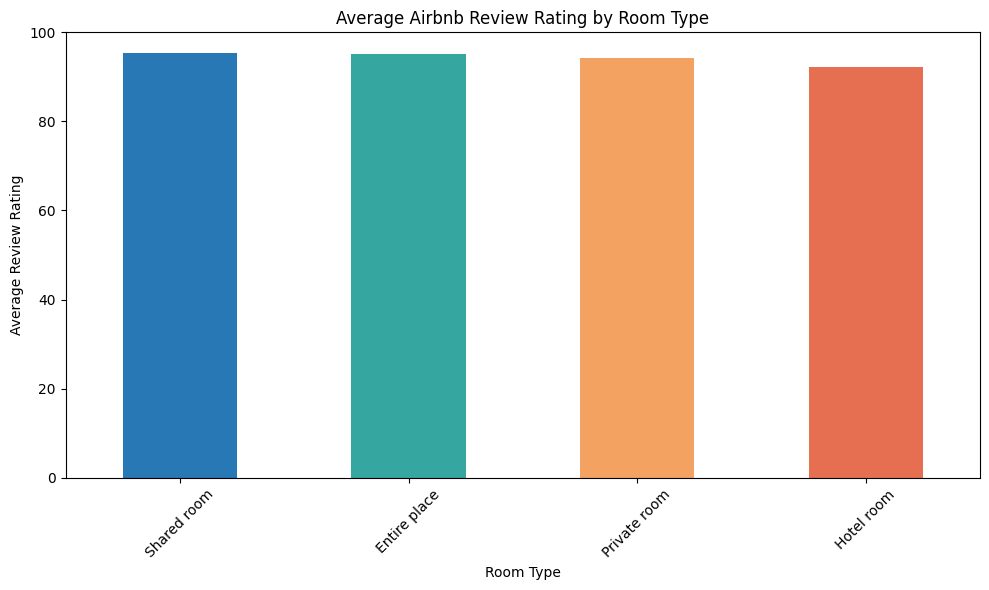

In [0]:
import matplotlib.pyplot as plt

# Sort room types by average rating.
rating_chart = rating_summary.sort_values(
    by="average_rating",
    ascending=False
)

# Create the bar chart.
plt.figure(figsize=(10, 6))

rating_chart["average_rating"].plot(
    kind="bar",
    color=["#2878B5", "#35A7A0", "#F4A261", "#E76F51"]
)

# Add chart title and labels.
plt.title("Average Airbnb Review Rating by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Average Review Rating")

# Set the rating scale.
plt.ylim(0, 100)

# Improve readability.
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Which room types and property types are most common

MATCHED LISTINGS BY ROOM TYPE


room_type,count
Entire place,32
Private room,10


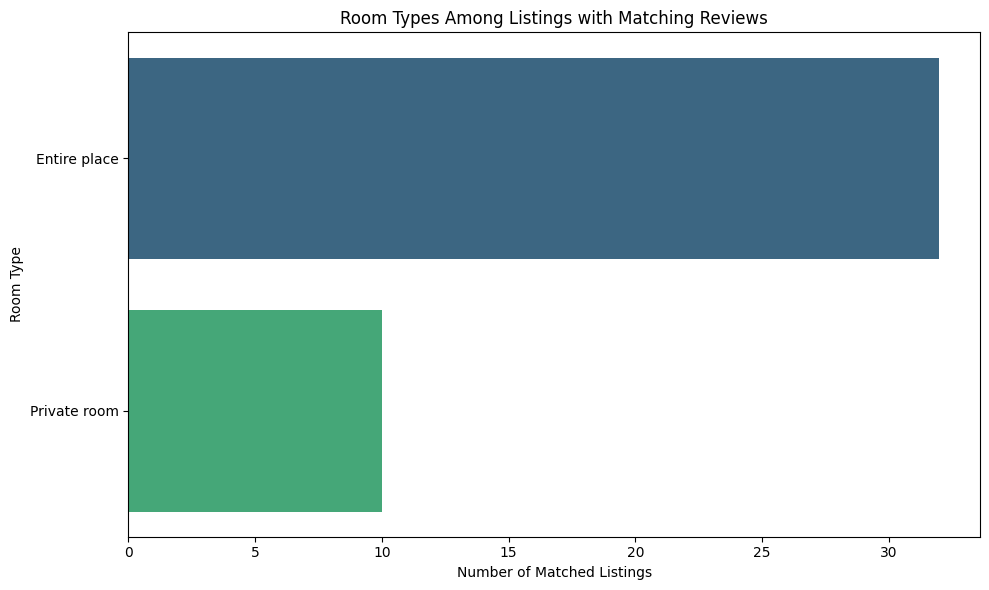

TOP PROPERTY TYPES IN MATCHED DATA


property_type,count
Entire loft,20
Entire condominium,9
Private room in condominium,5
Private room in loft,3
Entire townhouse,1
Private room in townhouse,1
Private room in boat,1
Entire guesthouse,1
Entire guest suite,1


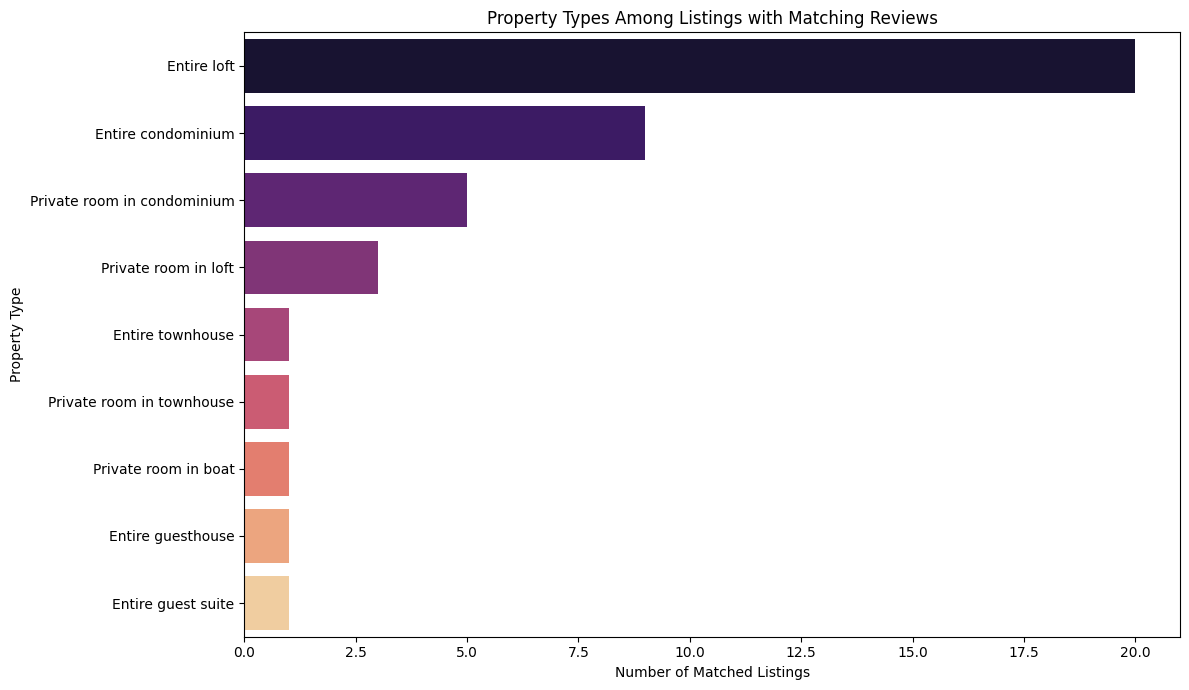

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------------
# 1. PREPARE THE MATCHED LISTINGS
# -----------------------------------------

# Keep one record per unique listing
matched_unique = matched_listings.drop_duplicates(
    subset="listing_id"
).copy()


# -----------------------------------------
# 2. ROOM TYPE ANALYSIS
# -----------------------------------------

# Remove missing and null room types
matched_room_data = matched_unique[
    matched_unique["room_type"].notna() &
    (matched_unique["room_type"] != "null")
]

# Count matched listings by room type
matched_room_counts = (
    matched_room_data["room_type"].value_counts()
)

# Display results
print("MATCHED LISTINGS BY ROOM TYPE")
display(matched_room_counts.reset_index())

# Create room type chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=matched_room_counts.values,
    y=matched_room_counts.index,
    hue=matched_room_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Room Types Among Listings with Matching Reviews")
plt.xlabel("Number of Matched Listings")
plt.ylabel("Room Type")
plt.tight_layout()
plt.show()


# -----------------------------------------
# 3. PROPERTY TYPE ANALYSIS
# -----------------------------------------

# Remove missing property types
matched_property_data = matched_unique[
    matched_unique["property_type"].notna() &
    (matched_unique["property_type"] != "null")
]

# Count matched listings by property type
matched_property_counts = (
    matched_property_data["property_type"].value_counts()
)

# Select the 10 most common property types
matched_top_properties = matched_property_counts.head(10)

# Display results
print("TOP PROPERTY TYPES IN MATCHED DATA")
display(matched_top_properties.reset_index())

# Create property type chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=matched_top_properties.values,
    y=matched_top_properties.index,
    hue=matched_top_properties.index,
    palette="magma",
    legend=False
)

plt.title("Property Types Among Listings with Matching Reviews")
plt.xlabel("Number of Matched Listings")
plt.ylabel("Property Type")
plt.tight_layout()
plt.show() 
 
 
 

 **What listing characteristics are associated with higher advertised prices?**

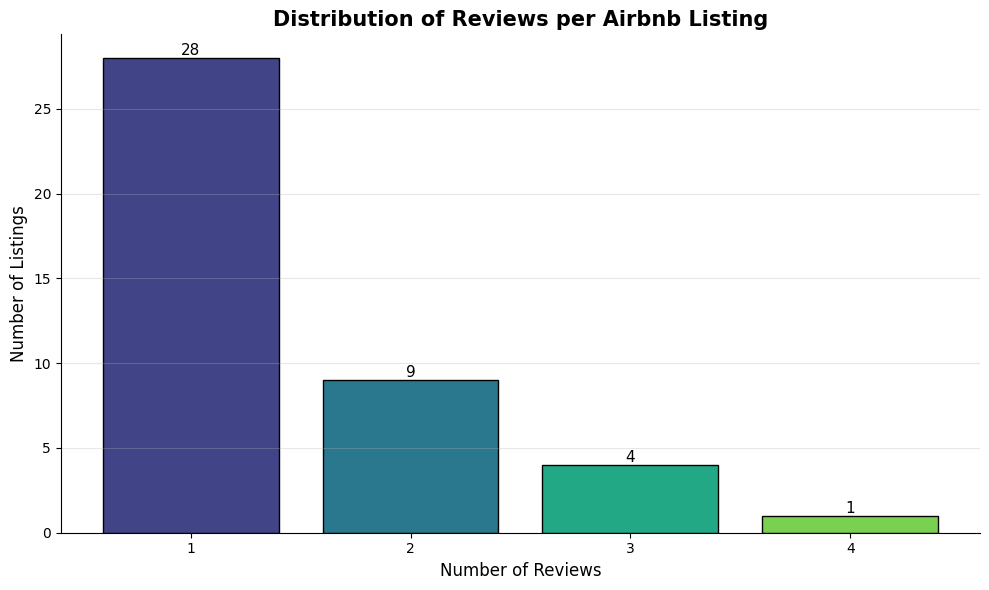

In [0]:
 # Import the required libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Count how many listings received each number of reviews
review_counts = (
    matched_reviews["total_reviews"]
    .value_counts()
    .sort_index()
)

# Create the chart
plt.figure(figsize=(10, 6))

# Draw the bar chart
bars = plt.bar(
    review_counts.index.astype(str),
    review_counts.values,
    color=sns.color_palette("viridis", len(review_counts)),
    edgecolor="black"
)

# Add values above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        int(bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=11
    )

# Add chart title and labels
plt.title(
    "Distribution of Reviews per Airbnb Listing",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Reviews", fontsize=12)
plt.ylabel("Number of Listings", fontsize=12)

# Improve chart appearance
plt.grid(axis="y", alpha=0.3)
sns.despine()
plt.tight_layout()

# Display the chart
plt.show()

In [0]:
# Build the per-listing review summary for the matched listings:
# review counts joined with each listing's room type.
listing_review_summary = (
    matched_reviews
    .merge(
        listing[["listing_id", "room_type"]].drop_duplicates(
            subset="listing_id"
        ),
        on="listing_id",
        how="left"
    )
)

 # -----------------------------------------
# 1. REVIEW ACTIVITY BY ROOM TYPE
# -----------------------------------------

review_room_summary = (
    listing_review_summary
    .groupby("room_type")
    .agg(
        listing_count=("listing_id", "nunique"),
        average_reviews=("total_reviews", "mean"),
        median_reviews=("total_reviews", "median"),
        total_reviews=("total_reviews", "sum")
    )
    .sort_values("average_reviews", ascending=False)
)

print("REVIEW ACTIVITY BY ROOM TYPE")
display(review_room_summary)


# -----------------------------------------
# 2. REVIEW ACTIVITY BY PROPERTY TYPE
# -----------------------------------------

# Add property type to the matched listing summary
matched_property_summary = (
    listing_review_summary
    .merge(
        listing[["listing_id", "property_type"]].drop_duplicates(
            subset="listing_id"
        ),
        on="listing_id",
        how="left"
    )
)

review_property_summary = (
    matched_property_summary
    .groupby("property_type")
    .agg(
        listing_count=("listing_id", "nunique"),
        average_reviews=("total_reviews", "mean"),
        total_reviews=("total_reviews", "sum")
    )
    .sort_values("average_reviews", ascending=False)
)

print("REVIEW ACTIVITY BY PROPERTY TYPE")
display(review_property_summary.head(10))

REVIEW ACTIVITY BY ROOM TYPE


listing_count,average_reviews,median_reviews,total_reviews
32,1.53125,1.0,49
10,1.3,1.0,13


REVIEW ACTIVITY BY PROPERTY TYPE


listing_count,average_reviews,total_reviews
1,4.0,4
1,2.0,2
1,2.0,2
1,2.0,2
20,1.6,32
3,1.3333333333333333,4
9,1.1111111111111112,10
1,1.0,1
5,1.0,5


How do host characteristics and performance indicators vary across cities?

In [0]:
 # 1. CONNECT REVIEW ACTIVITY TO HOST INFORMATION
host_review_data = listing_review_summary.merge(
    listing[
        [
            "listing_id",
            "host_is_superhost",
            "host_response_time",
            "host_response_rate",
            "host_acceptance_rate"
        ]
    ].drop_duplicates(subset="listing_id"),
    on="listing_id",
    how="left"
)

# 2. REVIEW ACTIVITY BY SUPERHOST STATUS
superhost_reviews = (
    host_review_data
    .groupby("host_is_superhost")
    .agg(
        listing_count=("listing_id", "nunique"),
        average_reviews=("total_reviews", "mean"),
        total_reviews=("total_reviews", "sum")
    )
)

print("REVIEW ACTIVITY BY SUPERHOST STATUS")
display(superhost_reviews)

# 3. REVIEW ACTIVITY BY HOST RESPONSE TIME
response_reviews = (
    host_review_data
    .groupby("host_response_time")
    .agg(
        listing_count=("listing_id", "nunique"),
        average_reviews=("total_reviews", "mean")
    )
    .sort_values("average_reviews", ascending=False)
)

print("REVIEW ACTIVITY BY HOST RESPONSE TIME")
display(response_reviews)

REVIEW ACTIVITY BY SUPERHOST STATUS


listing_count,average_reviews,total_reviews
26,1.5,39
16,1.4375,23


REVIEW ACTIVITY BY HOST RESPONSE TIME


listing_count,average_reviews
20,1.8
6,1.6666666666666667
11,1.0
5,1.0


Which Airbnb listings receive the highest review activity?

TOP 10 MOST-REVIEWED LISTINGS


listing_id,total_reviews,first_review,last_review
18305959,8,2018-09-30,2019-01-01
18299179,7,2018-09-30,2019-06-02
6510110,6,2018-06-03,2019-06-02
18609786,6,2018-06-03,2019-06-02
20806949,6,2018-06-03,2019-06-02
29348181,5,2019-04-22,2019-04-22
28355862,5,2018-09-30,2019-04-22
22398638,5,2018-06-03,2019-06-02
18411135,5,2018-06-03,2019-06-02
24030305,5,2018-06-03,2019-06-02


REVIEW ACTIVITY SUMMARY


count    7084.000000
mean        1.411632
std         0.703321
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         8.000000
Name: total_reviews, dtype: float64

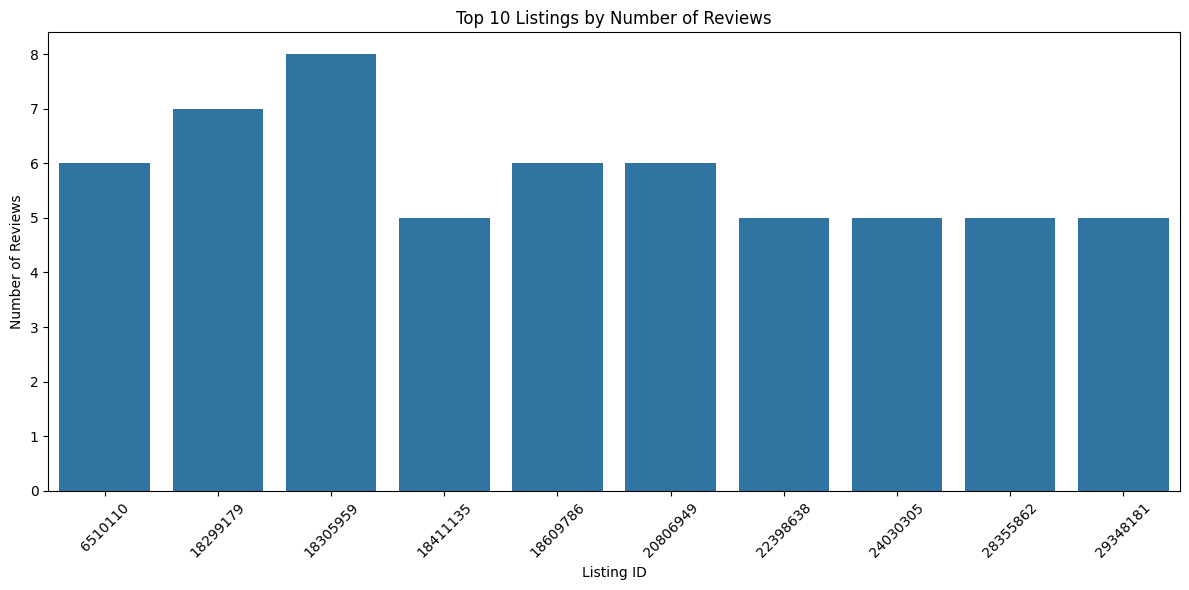

In [0]:
 # Import pandas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Count the number of reviews for each listing
reviews_per_listing = (
    reviews.groupby("listing_id")
    .agg(
        total_reviews=("review_id", "nunique"),
        first_review=("date", "min"),
        last_review=("date", "max")
    )
    .reset_index()
)

# 2. Sort listings from highest to lowest review activity
top_reviewed = reviews_per_listing.sort_values(
    "total_reviews", ascending=False
)

# 3. Display the top 10 most-reviewed listings
print("TOP 10 MOST-REVIEWED LISTINGS")
display(top_reviewed.head(10))

# 4. Review activity distribution
print("REVIEW ACTIVITY SUMMARY")
display(reviews_per_listing["total_reviews"].describe())

# 5. Plot the top 10 listings
top_10 = top_reviewed.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10,
    x="listing_id",
    y="total_reviews"
)
plt.title("Top 10 Listings by Number of Reviews")
plt.xlabel("Listing ID")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**How do listing-level review scores differ across property types and locations?**

In [0]:
 # 1. Count reviews for each listing
review_counts = (
    reviews.groupby("listing_id")
    .agg(
        total_reviews=("review_id", "nunique")
    )
    .reset_index()
)

# 2. Add listing-level review ratings and property details
review_rating_data = review_counts.merge(
    listing[
        [
            "listing_id",
            "city",
            "property_type",
            "room_type",
            "review_scores_rating"
        ]
    ].drop_duplicates(subset="listing_id"),
    on="listing_id",
    how="inner"
)

# 3. Convert the text review ratings into numeric values
review_rating_data["review_scores_rating"] = pd.to_numeric(
    review_rating_data["review_scores_rating"],
    errors="coerce"
)

# 4. Keep listings with available ratings
review_rating_data = review_rating_data.dropna(
    subset=["review_scores_rating"]
)

# 4. Summarise ratings and review activity by city
reviews_city_rating = (
    review_rating_data
    .groupby("city")
    .agg(
        listing_count=("listing_id", "nunique"),
        average_rating=("review_scores_rating", "mean"),
        average_reviews=("total_reviews", "mean")
    )
    .sort_values("average_rating", ascending=False)
)

print("MATCHED LISTINGS: RATINGS AND REVIEW ACTIVITY BY CITY")
display(reviews_city_rating)

# 5. Summarise ratings by property type
reviews_property_rating = (
    review_rating_data
    .groupby("property_type")
    .agg(
        listing_count=("listing_id", "nunique"),
        average_rating=("review_scores_rating", "mean"),
        average_reviews=("total_reviews", "mean")
    )
    .sort_values("average_rating", ascending=False)
)

print("MATCHED LISTINGS: RATINGS BY PROPERTY TYPE")
display(reviews_property_rating.head(10))

MATCHED LISTINGS: RATINGS AND REVIEW ACTIVITY BY CITY


listing_count,average_rating,average_reviews
42,95.38095238095238,1.4761904761904763


MATCHED LISTINGS: RATINGS BY PROPERTY TYPE


listing_count,average_rating,average_reviews
1,98.0,2.0
1,98.0,2.0
5,97.6,1.0
1,97.0,2.0
3,95.66666666666667,1.3333333333333333
20,95.55,1.6
1,95.0,4.0
9,93.22222222222223,1.1111111111111112
1,93.0,1.0


Are there observable relationships between review activity and listing-level review ratings?

MATCHED LISTINGS AVAILABLE FOR CORRELATION
Number of listings: 42


listing_id,total_reviews,review_scores_rating,city,room_type
1266367,1,87,Paris,Entire place
1349928,2,94,Paris,Entire place
2407736,1,98,Paris,Entire place
2444174,1,94,Paris,Entire place
4023152,1,93,Paris,Entire place


PEARSON CORRELATION
Correlation: -0.17879079387167773
P-value: 0.25726198413334045
SPEARMAN CORRELATION
Correlation: -0.2592744524499087
P-value: 0.09730296045291001


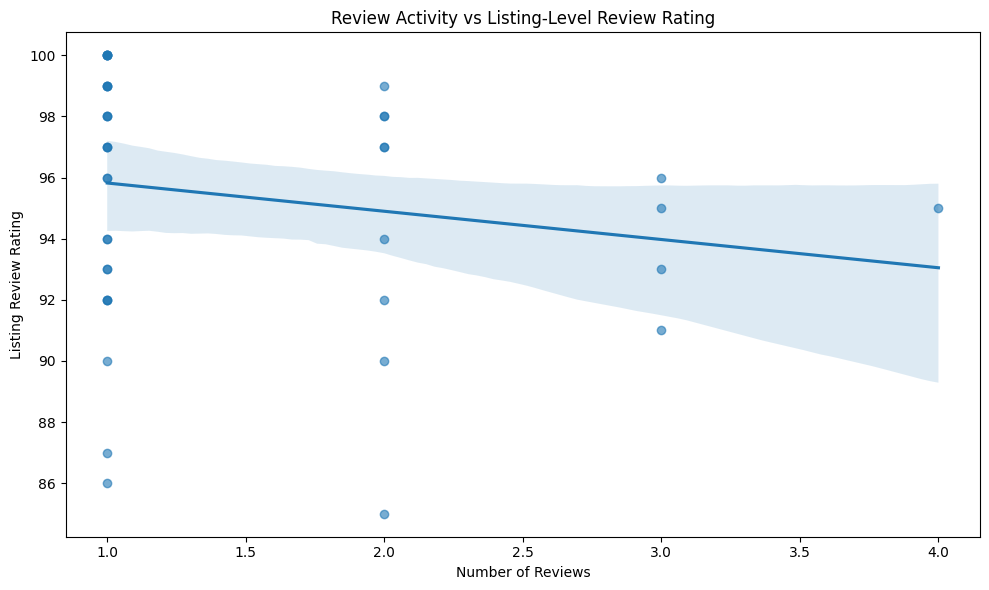

In [0]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# 1. Count unique reviews per listing
review_activity = (
    reviews.groupby("listing_id")
    .agg(
        total_reviews=("review_id", "nunique")
    )
    .reset_index()
)

# 2. Add listing-level ratings
review_rating_relationship = review_activity.merge(
    listing[
        ["listing_id", "review_scores_rating", "city", "room_type"]
    ].drop_duplicates(subset="listing_id"),
    on="listing_id",
    how="inner"
)

# 3. Convert the text review ratings into numeric values
review_rating_relationship["review_scores_rating"] = pd.to_numeric(
    review_rating_relationship["review_scores_rating"],
    errors="coerce"
)

# 4. Remove listings without ratings
review_rating_relationship = review_rating_relationship.dropna(
    subset=["review_scores_rating", "total_reviews"]
)

print("MATCHED LISTINGS AVAILABLE FOR CORRELATION")
print("Number of listings:", len(review_rating_relationship))
display(review_rating_relationship.head())

# 4. Calculate Pearson and Spearman correlations
pearson_corr, pearson_p = pearsonr(
    review_rating_relationship["total_reviews"],
    review_rating_relationship["review_scores_rating"]
)

spearman_corr, spearman_p = spearmanr(
    review_rating_relationship["total_reviews"],
    review_rating_relationship["review_scores_rating"]
)

print("PEARSON CORRELATION")
print("Correlation:", pearson_corr)
print("P-value:", pearson_p)

print("SPEARMAN CORRELATION")
print("Correlation:", spearman_corr)
print("P-value:", spearman_p)

# 5. Plot review activity against rating
plt.figure(figsize=(10, 6))
sns.regplot(
    data=review_rating_relationship,
    x="total_reviews",
    y="review_scores_rating",
    scatter_kws={"alpha": 0.6}
)
plt.title("Review Activity vs Listing-Level Review Rating")
plt.xlabel("Number of Reviews")
plt.ylabel("Listing Review Rating")
plt.tight_layout()
plt.show()

**Can listing prices be estimated using property characteristics and other available listing information?**

- prepare review activity information

In [0]:
 # 1. Count the reviews for each listing
review_counts = (
    reviews.groupby("listing_id")
    .agg(
        total_reviews=("review_id", "nunique")
    )
    .reset_index()
)

# 2. Compare review IDs with listing IDs
matched_review_ids = set(review_counts["listing_id"])
listing_ids = set(listing["listing_id"])

matched_count = len(matched_review_ids.intersection(listing_ids))
unmatched_count = len(matched_review_ids.difference(listing_ids))

print("REVIEW DATA COVERAGE")
print("Unique listings in Reviews:", len(matched_review_ids))
print("Matched listing IDs:", matched_count)
print("Unmatched listing IDs:", unmatched_count)

# 3. Display listings with the highest review activity
print("TOP 10 LISTINGS BY REVIEW COUNT")
display(
    review_counts.sort_values(
        "total_reviews",
        ascending=False
    ).head(10)
)

REVIEW DATA COVERAGE
Unique listings in Reviews: 7084
Matched listing IDs: 42
Unmatched listing IDs: 7042
TOP 10 LISTINGS BY REVIEW COUNT


listing_id,total_reviews
18305959,8
18299179,7
6510110,6
18609786,6
20806949,6
29348181,5
28355862,5
22398638,5
18411135,5
24030305,5


In [0]:
 # Import pandas
import pandas as pd

# 1. Count reviews per listing
dashboard_reviews = (
    reviews.groupby("listing_id")
    .agg(
        total_reviews=("review_id", "nunique")
    )
    .reset_index()
)

# 2. Sort from most reviewed to least reviewed
dashboard_reviews = dashboard_reviews.sort_values(
    "total_reviews",
    ascending=False
)

# 3. Display the results
print("REVIEW ACTIVITY SUMMARY")
display(dashboard_reviews.head(10))

# 4. Save the review summary as a Databricks table
spark.createDataFrame(dashboard_reviews).write.mode(
    "overwrite"
).saveAsTable("workspace.pandas.airbnb_dashboard_reviews")

print("Review dashboard table saved successfully!")

REVIEW ACTIVITY SUMMARY


listing_id,total_reviews
18305959,8
18299179,7
6510110,6
18609786,6
20806949,6
29348181,5
28355862,5
22398638,5
18411135,5
24030305,5


Review dashboard table saved successfully!


**Prepare the Listings and Reviews datasets**

In [0]:
 # Count unique listing IDs in both datasets.
print("LISTINGS UNIQUE IDs:", listing["listing_id"].nunique())
print("REVIEWS UNIQUE IDs:", reviews["listing_id"].nunique())

# Find the listing IDs that appear in both datasets.
matching_ids = set(listing["listing_id"]).intersection(
    set(reviews["listing_id"])
)

# Display the number of matching listings.
print("\nMATCHING LISTING IDs:", len(matching_ids))

LISTINGS UNIQUE IDs: 2953
REVIEWS UNIQUE IDs: 7084

MATCHING LISTING IDs: 42


In [0]:
 # Count reviews for each listing.
reviews_per_listing = (
    reviews.groupby("listing_id")
    .agg(
        total_reviews=("review_id", "count")
    )
    .reset_index()
)

# Keep only listings that also appear in the Listings dataset.
matched_reviews = reviews_per_listing[
    reviews_per_listing["listing_id"].isin(matching_ids)
].copy()

# Display the first 10 matching listings.
display(matched_reviews.head(10))

# Check how many listings were matched.
print("Matched listings:", len(matched_reviews))

listing_id,total_reviews
1266367,1
1349928,2
2407736,1
2444174,1
4023152,1
4908402,4
6978581,1
7549918,1
9462264,3
9571443,3


Matched listings: 42


In [0]:
 # Select listing IDs and their review ratings.
listing_ratings = listing[
    ["listing_id", "review_scores_rating"]
].copy()

# Merge review counts with listing ratings.
review_rating_analysis = pd.merge(
    matched_reviews,
    listing_ratings,
    on="listing_id",
    how="inner"
)

# Remove records without a review rating.
review_rating_analysis = review_rating_analysis.dropna(
    subset=["review_scores_rating"]
)

# Display the combined dataset.
display(review_rating_analysis.head(10))

# Display the number of usable records.
print("Usable matched listings:", len(review_rating_analysis))

listing_id,total_reviews,review_scores_rating
1266367,1,87.0
1349928,2,94.0
2407736,1,98.0
2444174,1,94.0
4023152,1,93.0
4908402,4,95.0
6978581,1,98.0
7549918,1,97.0
9462264,3,91.0
9571443,3,95.0


Usable matched listings: 42


The Pearson correlation analysis produced a coefficient of -0.1788, indicating a weak negative association between review activity and listing-level review ratings. This suggests that listings with higher recorded review counts tended to have slightly lower ratings within the matched sample. However, only a small number of listings could be matched between the two datasets, limiting the reliability and generalisability of this finding. The result should therefore be treated as exploratory rather than conclusive.

In [0]:
 # Calculate the Pearson correlation between review count and rating.
review_correlation = review_rating_analysis[
    ["total_reviews", "review_scores_rating"]
].corr(method="pearson")

# Display the correlation matrix.
print("CORRELATION MATRIX")
display(review_correlation)

# Extract the correlation value.
correlation_value = review_correlation.loc[
    "total_reviews", "review_scores_rating"
]

print("\nPEARSON CORRELATION:", correlation_value)

CORRELATION MATRIX


total_reviews,review_scores_rating
1.0,-0.1787907938716777
-0.1787907938716777,1.0



PEARSON CORRELATION: -0.1787907938716777


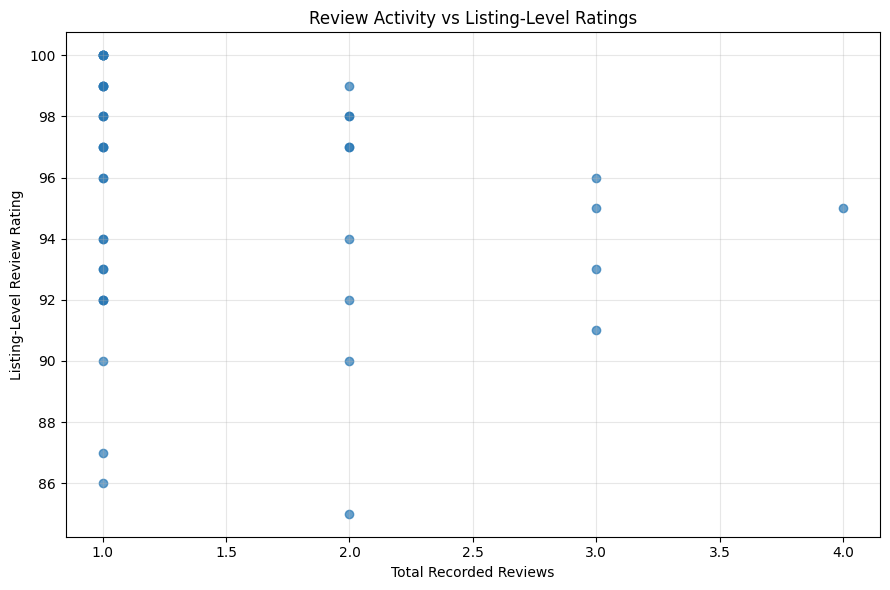

In [0]:
import matplotlib.pyplot as plt

# Create a scatter plot.
plt.figure(figsize=(9, 6))

plt.scatter(
    review_rating_analysis["total_reviews"],
    review_rating_analysis["review_scores_rating"],
    color="#2878B5",
    alpha=0.7
)

# Add chart title and labels.
plt.title("Review Activity vs Listing-Level Ratings")
plt.xlabel("Total Recorded Reviews")
plt.ylabel("Listing-Level Review Rating")

# Add grid lines.
plt.grid(True, alpha=0.3)

# Display the chart.
plt.tight_layout()
plt.show()

Task 3: Formulate and Test Hypotheses
For this task, we need to move beyond describing the Airbnb data. We will use statistical tests to determine whether the patterns we observed are statistically significant.

We'll develop three hypotheses based on your research problem:

How do Airbnb advertised prices vary across cities, room types and accommodation characteristics, and what factors are associated with these price differences?
1. Proposed hypotheses and statistical tests
I recommend using Cape Town for the price and accommodation comparisons because it has the largest number of listings in your dataset (513). Analysing one city at a time also avoids mixing prices from different countries and currencies.
Hypothesis	Variables	Proposed statistical test
H1: Advertised prices differ across room types in Cape Town.	Room type and price	Kruskal-Wallis test
H2: Accommodation capacity is associated with advertised price in Cape Town.	Accommodates and price	Spearman correlation
H3: Listing-level review ratings differ across room types.	Room type and review rating	Kruskal-Wallis test

We will test each hypothesis separately.
2. Hypothesis 1: Advertised prices differ across room types
Research question: Do Airbnb listings with different room types have significantly different advertised prices in Cape Town?

Null hypothesis (H₀): There is no statistically significant difference in advertised prices across the room types in Cape Town.

Alternative hypothesis (H₁): At least one room type has a different advertised price distribution from the others.

Variables:
- Independent variable: room_type (categorical).
- Dependent variable: price (numerical).
Statistical test: Kruskal-Wallis H-test

We will use this test because:
- We are comparing more than two independent room-type groups.
- Advertised prices have a wide range and some extreme values.
- The Kruskal-Wallis test does not require normally distributed price values.
Assumptions:
1. Observations are independent.
2. The groups are independent of one another.
3. The dependent variable is numerical or ordinal.
4. For interpreting the result specifically as a difference in medians, group distributions should have reasonably similar shapes.
Our significance level will be 0.05.
- If p-value is below 0.05, reject the null hypothesis.
- If p-value is 0.05 or above, fail to reject the null hypothesis.


In [0]:
 # Select listings from Cape Town with valid prices and room types.
cape_town_data = listing[
    (listing["city"] == "Cape Town") &
    (listing["room_type"] != "null") &
    (listing["price"].notna())
].copy()

# Display the number of listings in each room type.
print("CAPE TOWN LISTINGS BY ROOM TYPE")
print(cape_town_data["room_type"].value_counts())

# Display the total number of usable listings.
print("\nTOTAL USABLE LISTINGS:", len(cape_town_data))

CAPE TOWN LISTINGS BY ROOM TYPE
room_type
Entire place    250
Private room    249
Hotel room        8
Shared room       6
Name: count, dtype: int64

TOTAL USABLE LISTINGS: 513


In [0]:
 # Import the Kruskal-Wallis statistical test.
from scipy.stats import kruskal

# Create a separate price group for each room type.
room_groups = [
    group["price"].values
    for name, group in cape_town_data.groupby("room_type")
]

# Perform the Kruskal-Wallis test.
h_statistic, p_value = kruskal(*room_groups)

# Count the number of room types.
k = len(room_groups)

# Count the total number of listings used in the test.
n = len(cape_town_data)

# Calculate the effect size (epsilon-squared).
epsilon_squared = max(0, (h_statistic - k + 1) / (n - k))

# Display the statistical results.
print("KRUSKAL-WALLIS TEST RESULTS")
print("H-statistic:", h_statistic)
print("P-value:", p_value)
print("Effect size (Epsilon-squared):", epsilon_squared)

# Interpret the statistical significance using a 5% significance level.
if p_value < 0.05:
    print("\nDecision: Reject the null hypothesis.")
    print("There is a statistically significant difference in prices across room types.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a statistically significant price difference.")

KRUSKAL-WALLIS TEST RESULTS
H-statistic: 25.210920142872585
P-value: 1.3949367578395462e-05
Effect size (Epsilon-squared): 0.04363638534945498

Decision: Reject the null hypothesis.
There is a statistically significant difference in prices across room types.


In [0]:
# Remove the core-package overrides pulled in by the first install attempt.
%uv pip uninstall statsmodels patsy formulaic interface-meta narwhals numpy pandas scipy packaging python-dateutil tzdata typing-extensions wrapt

# Install a statsmodels version compatible with the runtime's numpy 2.3.4 / pandas 2.3.3 / scipy 1.16.3, without overriding them.
%uv pip install --no-deps "statsmodels==0.14.4" "patsy==1.0.3"

Using Python 3.12.3 environment at: /local_disk0/.ephemeral_nfs/envs/pythonEnv-5e8f5f28-e6c9-48a0-99f5-cfa79c87fecc
Uninstalled 13 packages in 169ms
 - formulaic==1.2.2
 - interface-meta==2.0.1
 - narwhals==2.28.0
 - numpy==2.5.4
 - packaging==26.3
 - pandas==3.1.1
 - patsy==1.0.3
 - python-dateutil==4.0.0
 - scipy==1.18.1
 - statsmodels==0.15.0
 - typing-extensions==4.16.0
 - tzdata==2026.6
 - wrapt==2.5.2
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
Using Python 3.12.3 environment at: /local_disk0/.ephemeral_nfs/envs/pythonEnv-5e8f5f28-e6c9-48a0-99f5-cfa79c87fecc
Resolved 2 packages in 34ms
 Downloaded statsmodels
Prepared 1 package in 194ms
Installed 2 packages in 175ms
 + patsy==1.0.3
 + statsmodels==0.14.4
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
 # Import the tools needed for pairwise comparisons.
from scipy.stats import mannwhitneyu
from itertools import combinations
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Convert the text prices into numeric values.
prices_numeric = pd.to_numeric(
    cape_town_data["price"],
    errors="coerce"
)

# Create an empty list to store the comparison results.
pairwise_results = []

# Get all possible pairs of room types.
room_types = cape_town_data["room_type"].unique()

# Compare every room type against every other room type.
for room1, room2 in combinations(room_types, 2):

    # Extract the numeric prices for the first room type.
    prices1 = prices_numeric[
        cape_town_data["room_type"] == room1
    ].dropna()

    # Extract the numeric prices for the second room type.
    prices2 = prices_numeric[
        cape_town_data["room_type"] == room2
    ].dropna()

    # Perform the Mann-Whitney U-test.
    statistic, p_value = mannwhitneyu(
        prices1,
        prices2,
        alternative="two-sided"
    )

    # Save the comparison results.
    pairwise_results.append({
        "Room Type 1": room1,
        "Room Type 2": room2,
        "U-statistic": statistic,
        "Original P-value": p_value
    })

# Convert the results into a DataFrame.
pairwise_df = pd.DataFrame(pairwise_results)

# Apply the Holm correction to the p-values.
pairwise_df["Adjusted P-value"] = multipletests(
    pairwise_df["Original P-value"],
    method="holm"
)[1]

# Identify which comparisons are statistically significant.
pairwise_df["Significant"] = (
    pairwise_df["Adjusted P-value"] < 0.05
)

# Display the final pairwise comparison results.
print("PAIRWISE ROOM TYPE COMPARISONS")
print(pairwise_df.to_string(index=False))

PAIRWISE ROOM TYPE COMPARISONS
 Room Type 1  Room Type 2  U-statistic  Original P-value  Adjusted P-value  Significant
Private room Entire place      21169.0      6.278800e-10      3.767280e-09         True
Private room  Shared room       1098.5      4.919066e-02      1.326195e-01        False
Private room   Hotel room        372.0      2.576910e-03      1.288455e-02         True
Entire place  Shared room       1200.5      1.202698e-02      4.810792e-02         True
Entire place   Hotel room        671.0      1.137475e-01      1.326195e-01        False
 Shared room   Hotel room          8.0      4.420649e-02      1.326195e-01        False


Check median prices by room type

In [0]:
 # Convert the text prices into numeric values.
prices_numeric = pd.to_numeric(
    cape_town_data["price"],
    errors="coerce"
)

# Calculate the median advertised price for each room type.
median_prices = (
    prices_numeric.groupby(cape_town_data["room_type"])
    .median()
    .sort_values(ascending=False)
)

# Display the median prices.
print("MEDIAN PRICE BY ROOM TYPE")
print(median_prices)

MEDIAN PRICE BY ROOM TYPE
room_type
Hotel room      875.0
Entire place    750.0
Private room    519.0
Shared room     240.0
Name: price, dtype: float64


H2: Is accommodation capacity associated with advertised price in Cape Town?
We want to investigate whether Airbnb listings that accommodate more guests tend to have higher advertised prices.

Hypotheses
- H₀: There is no statistically significant association between accommodation capacity and advertised price.
- H₁: There is a statistically significant association between accommodation capacity and advertised price.
Variables
- Accommodation capacity: accommodates
- Advertised price: price
Statistical test: Spearman's rank correlation. This is suitable because accommodation capacity is a numerical variable with discrete values, and prices may not be normally distributed.

In [0]:
 # Import pandas for data preparation.
import pandas as pd

# Create a copy of the Cape Town dataset.
capacity_data = cape_town_data.copy()

# Convert accommodation capacity into numeric values.
capacity_data["accommodates"] = pd.to_numeric(
    capacity_data["accommodates"],
    errors="coerce"
)

# Remove rows where accommodation capacity or price is missing.
capacity_data = capacity_data.dropna(
    subset=["accommodates", "price"]
)

# Display the number of usable records.
print("TOTAL USABLE LISTINGS:", len(capacity_data))

# Display the accommodation capacity counts.
print("\nACCOMMODATION CAPACITY COUNTS:")
print(capacity_data["accommodates"].value_counts().sort_index())

TOTAL USABLE LISTINGS: 513

ACCOMMODATION CAPACITY COUNTS:
accommodates
1     36
2    410
3     35
4     29
5      1
6      2
Name: count, dtype: int64


In [0]:
# Import Spearman's correlation test.
from scipy.stats import spearmanr

# Calculate Spearman's correlation between capacity and price.
correlation, p_value = spearmanr(
    capacity_data["accommodates"],
    capacity_data["price"]
)

# Display the results.
print("SPEARMAN CORRELATION RESULTS")
print("--------------------------------")
print("Spearman correlation:", correlation)
print("P-value:", p_value)

# Interpret the strength and direction of the relationship.
if correlation > 0:
    print("\nDirection: Positive association.")
elif correlation < 0:
    print("\nDirection: Negative association.")
else:
    print("\nDirection: No association.")

# Check statistical significance.
if p_value < 0.05:
    print("Decision: Reject the null hypothesis.")
    print("There is a statistically significant association.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a statistically significant association.")

SPEARMAN CORRELATION RESULTS
--------------------------------
Spearman correlation: 0.1684891215061819
P-value: 0.0001259060661599539

Direction: Positive association.
Decision: Reject the null hypothesis.
There is a statistically significant association.


H3: Do review ratings differ across Airbnb room types in Cape Town?
We want to investigate whether entire places, private rooms, hotel rooms and shared rooms receive different listing-level review ratings.

Hypotheses
- H₀: There is no statistically significant difference in review ratings across the four room types.
- H₁: At least one room type has a statistically different review rating distribution.
Variables
- Independent variable: room_type
- Dependent variable: review_scores_rating
Statistical test: Kruskal-Wallis H-test.

We will use this test because we are comparing ratings across four independent groups, and ratings may not follow a normal distribution.

In [0]:
 # Create a copy of the Cape Town listings dataset.
rating_data = cape_town_data.copy()

# Convert review ratings into numeric values.
rating_data["review_scores_rating"] = pd.to_numeric(
    rating_data["review_scores_rating"],
    errors="coerce"
)

# Remove listings without a valid review rating.
rating_data = rating_data.dropna(
    subset=["review_scores_rating"]
)

# Count the listings with valid ratings in each room type.
print("CAPE TOWN LISTINGS WITH VALID REVIEW RATINGS")
print(
    rating_data["room_type"].value_counts()
)

# Display the total number of usable listings.
print("\nTOTAL USABLE LISTINGS:", len(rating_data))

# Display average and median ratings by room type.
print("\nRATING SUMMARY BY ROOM TYPE")
print(
    rating_data.groupby("room_type")["review_scores_rating"]
    .agg(["count", "mean", "median", "min", "max"])
)

CAPE TOWN LISTINGS WITH VALID REVIEW RATINGS
room_type
Entire place    221
Private room    180
Hotel room        7
Shared room       4
Name: count, dtype: int64

TOTAL USABLE LISTINGS: 412

RATING SUMMARY BY ROOM TYPE
              count       mean  median   min    max
room_type                                          
Entire place    221  96.402715    98.0  40.0  100.0
Hotel room        7  96.428571   100.0  80.0  100.0
Private room    180  94.516667    97.0  20.0  100.0
Shared room       4  90.500000    88.5  85.0  100.0


In [0]:
 # Import the Kruskal-Wallis test.
from scipy.stats import kruskal

# Create separate rating groups for each room type.
rating_groups = [
    group["review_scores_rating"].values
    for name, group in rating_data.groupby("room_type")
]

# Perform the Kruskal-Wallis test.
h_statistic, p_value = kruskal(*rating_groups)

# Count the number of room types.
k = len(rating_groups)

# Count the total number of listings.
n = len(rating_data)

# Calculate the effect size.
epsilon_squared = max(
    0,
    (h_statistic - k + 1) / (n - k)
)

# Display the results.
print("KRUSKAL-WALLIS REVIEW RATING RESULTS")
print("--------------------------------------")
print("H-statistic:", h_statistic)
print("P-value:", p_value)
print("Effect size (Epsilon-squared):", epsilon_squared)

# Interpret the statistical significance.
if p_value < 0.05:
    print("\nDecision: Reject the null hypothesis.")
    print("There is a statistically significant difference in ratings across room types.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a statistically significant difference.")

KRUSKAL-WALLIS REVIEW RATING RESULTS
--------------------------------------
H-statistic: 8.25914318864499
P-value: 0.04094886705465694
Effect size (Epsilon-squared): 0.01289005683491419

Decision: Reject the null hypothesis.
There is a statistically significant difference in ratings across room types.


In [0]:
# Import the required statistical tools.
from scipy.stats import mannwhitneyu
from itertools import combinations
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Create an empty list to store comparison results.
rating_pairwise_results = []

# Get the available room types.
room_types = rating_data["room_type"].unique()

# Compare every possible pair of room types.
for room1, room2 in combinations(room_types, 2):

    # Extract ratings for the first room type.
    ratings1 = rating_data[
        rating_data["room_type"] == room1
    ]["review_scores_rating"]

    # Extract ratings for the second room type.
    ratings2 = rating_data[
        rating_data["room_type"] == room2
    ]["review_scores_rating"]

    # Perform the Mann-Whitney U-test.
    statistic, p_value = mannwhitneyu(
        ratings1,
        ratings2,
        alternative="two-sided",
        method="auto"
    )

    # Store the results.
    rating_pairwise_results.append({
        "Room Type 1": room1,
        "Room Type 2": room2,
        "U-statistic": statistic,
        "Original P-value": p_value
    })

# Convert the results into a DataFrame.
rating_pairwise_df = pd.DataFrame(rating_pairwise_results)

# Apply the Holm correction for multiple comparisons.
rating_pairwise_df["Adjusted P-value"] = multipletests(
    rating_pairwise_df["Original P-value"],
    method="holm"
)[1]

# Identify statistically significant comparisons.
rating_pairwise_df["Significant"] = (
    rating_pairwise_df["Adjusted P-value"] < 0.05
)

# Display the results.
print("PAIRWISE REVIEW RATING COMPARISONS")
print(rating_pairwise_df.to_string(index=False)) 

PAIRWISE REVIEW RATING COMPARISONS
 Room Type 1  Room Type 2  U-statistic  Original P-value  Adjusted P-value  Significant
Entire place Private room      22318.5          0.032276          0.193656        False
Entire place  Shared room        658.0          0.088687          0.443437        False
Entire place   Hotel room        606.5          0.322554          0.676828        False
Private room  Shared room        503.0          0.169207          0.676828        False
Private room   Hotel room        448.0          0.188376          0.676828        False
 Shared room   Hotel room          8.0          0.275654          0.676828        False


In [0]:
%uv pip install --no-deps seaborn

Using Python 3.12.3 environment at: /local_disk0/.ephemeral_nfs/envs/pythonEnv-4a33c0eb-9076-4e35-ae4c-833db4f246a2
Resolved 1 package in 113ms
Prepared 1 package in 87ms
Installed 1 package in 9ms
 + seaborn==0.13.2
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


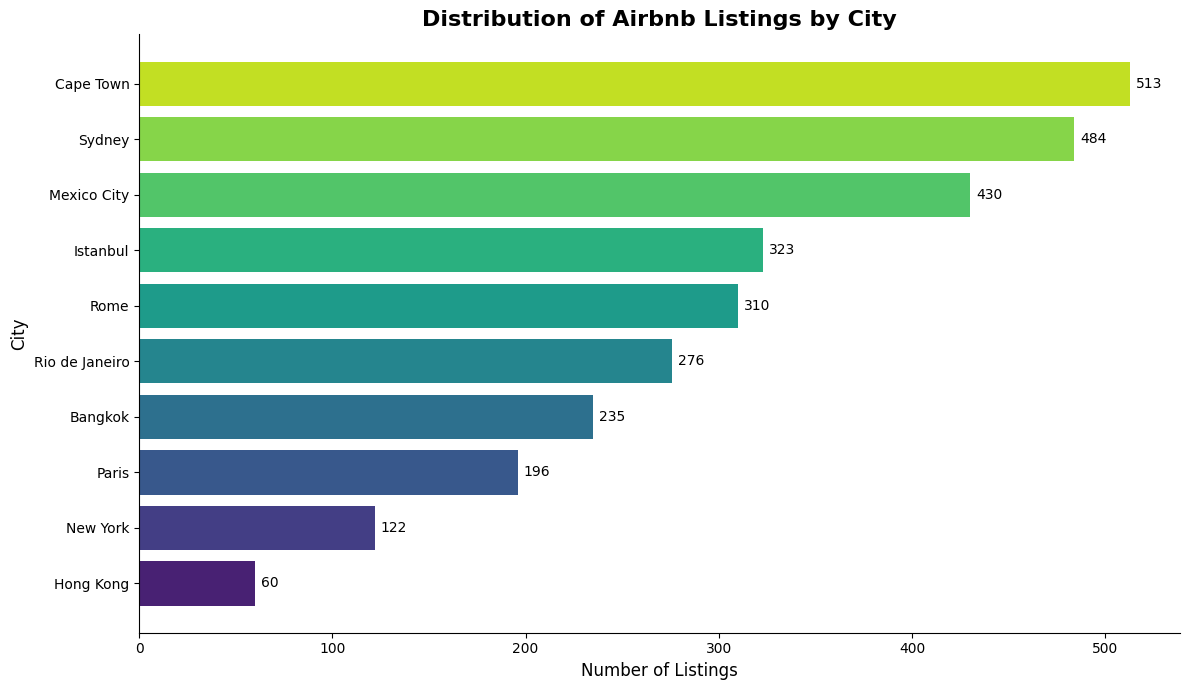

In [0]:
# Import the libraries needed for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Count the number of listings in each city
city_counts = listing["city"].value_counts()

# Remove unavailable city values if they exist
city_counts = city_counts.drop("null", errors="ignore")

# Sort cities from highest to lowest
city_counts = city_counts.sort_values(ascending=True)

# Set the chart size
plt.figure(figsize=(12, 7))

# Create the horizontal bar chart
bars = plt.barh(
    city_counts.index,
    city_counts.values,
    color=sns.color_palette("viridis", len(city_counts))
)

# Add a title and axis labels
plt.title("Distribution of Airbnb Listings by City",
          fontsize=16, fontweight="bold")

plt.xlabel("Number of Listings", fontsize=12)
plt.ylabel("City", fontsize=12)

# Display the listing count next to each bar
for bar in bars:
    plt.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center"
    )

# Remove unnecessary chart borders
plt.spines = None
sns.despine()

# Adjust spacing and display the chart
plt.tight_layout()
plt.show() 

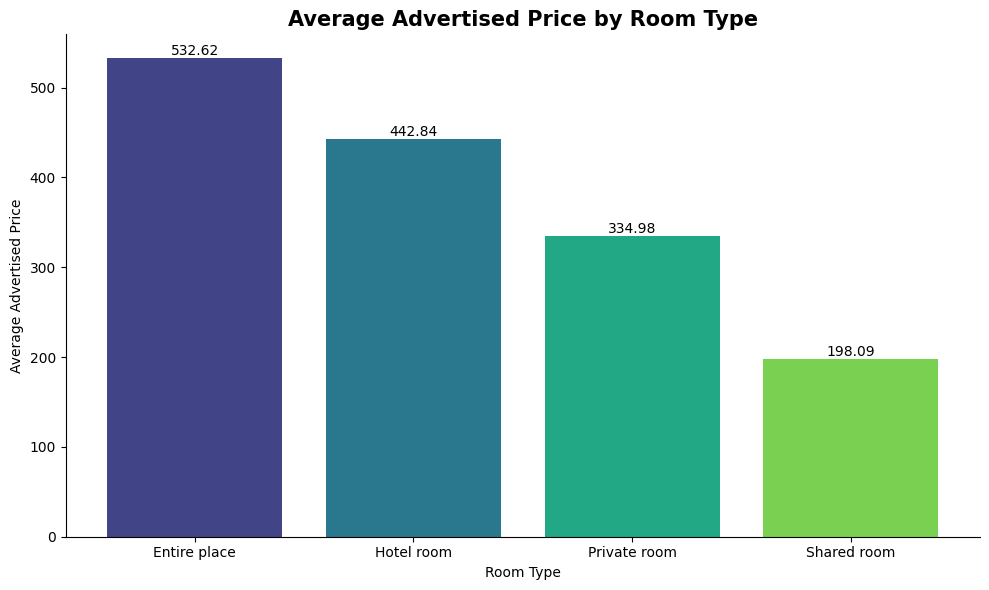

In [0]:
 # Import matplotlib and seaborn
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Keep only records with valid room types and prices
room_price = listing[
    (listing["room_type"] != "null") &
    (listing["price"].notna())
].copy()

# Convert the text prices into numeric values
room_price["price"] = pd.to_numeric(
    room_price["price"],
    errors="coerce"
)

# Calculate average price for each room type
room_avg_price = (
    room_price.groupby("room_type")["price"]
    .mean()
    .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(10, 6))

# Draw the bar chart
bars = plt.bar(
    room_avg_price.index,
    room_avg_price.values,
    color=sns.color_palette("viridis", len(room_avg_price))
)

# Add chart title and labels
plt.title("Average Advertised Price by Room Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Room Type")
plt.ylabel("Average Advertised Price")

# Display average values above the bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

# Improve chart appearance
sns.despine()
plt.tight_layout()
plt.show()

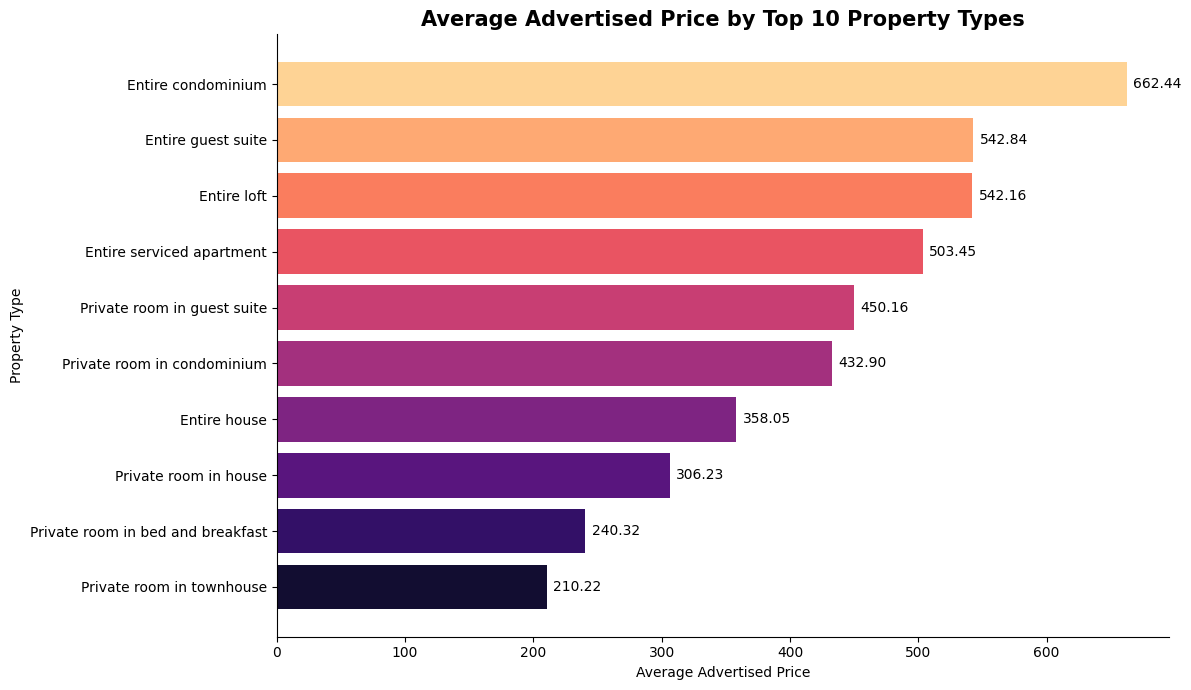

In [0]:
 # Import pandas for the numeric conversion
import pandas as pd

# Convert the text prices into numeric values
property_prices = listing.copy()
property_prices["price"] = pd.to_numeric(
    property_prices["price"],
    errors="coerce"
)

# Keep only listings with a valid price
property_prices = property_prices.dropna(subset=["price"])

# Calculate average price and listing count for each property type
property_summary = (
    property_prices
    .groupby("property_type")
    .agg(
        average_price=("price", "mean"),
        listing_count=("listing_id", "count")
    )
)

# Select the 10 most common property types
top_properties = (
    property_summary
    .sort_values("listing_count", ascending=False)
    .head(10)
    .sort_values("average_price")
)

# Create the horizontal bar chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_properties.index,
    top_properties["average_price"],
    color=sns.color_palette("magma", len(top_properties))
)

# Add chart title and labels
plt.title("Average Advertised Price by Top 10 Property Types",
          fontsize=15, fontweight="bold")
plt.xlabel("Average Advertised Price")
plt.ylabel("Property Type")

# Add price labels
for bar in bars:
    plt.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )

sns.despine()
plt.tight_layout()
plt.show()

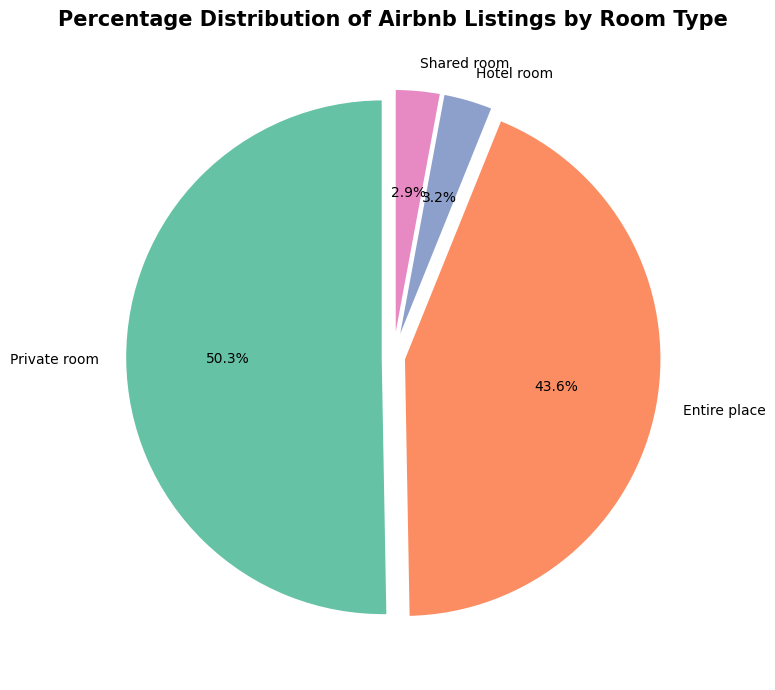

In [0]:
 # Count listings by room type
room_counts = (
    listing[listing["room_type"] != "null"]["room_type"]
    .value_counts()
)

# Create a pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    room_counts.values,
    labels=room_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(room_counts)),
    explode=[0.04] * len(room_counts),
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

# Add title
plt.title("Percentage Distribution of Airbnb Listings by Room Type",
          fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()

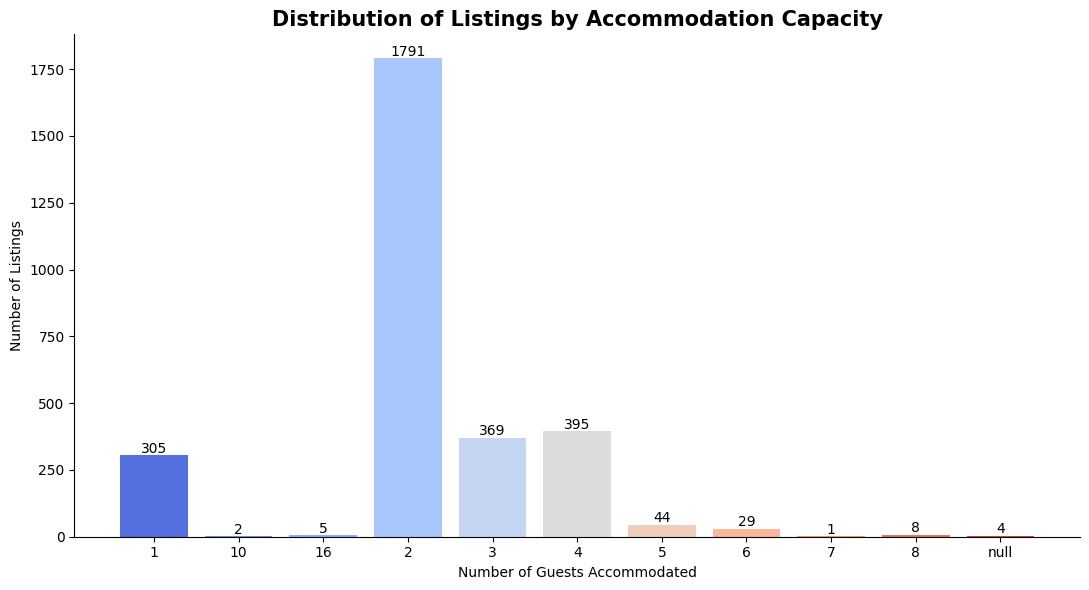

In [0]:
 # Remove missing accommodation capacity values
capacity_data = listing["accommodates"].dropna()

# Count listings by accommodation capacity
capacity_counts = capacity_data.value_counts().sort_index()

# Create the bar chart
plt.figure(figsize=(11, 6))

bars = plt.bar(
    capacity_counts.index.astype(str),
    capacity_counts.values,
    color=sns.color_palette("coolwarm", len(capacity_counts))
)

# Add title and axis labels
plt.title("Distribution of Listings by Accommodation Capacity",
          fontsize=15, fontweight="bold")
plt.xlabel("Number of Guests Accommodated")
plt.ylabel("Number of Listings")

# Add values above the bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10,
        f"{int(bar.get_height())}",
        ha="center"
    )

sns.despine()
plt.tight_layout()
plt.show()

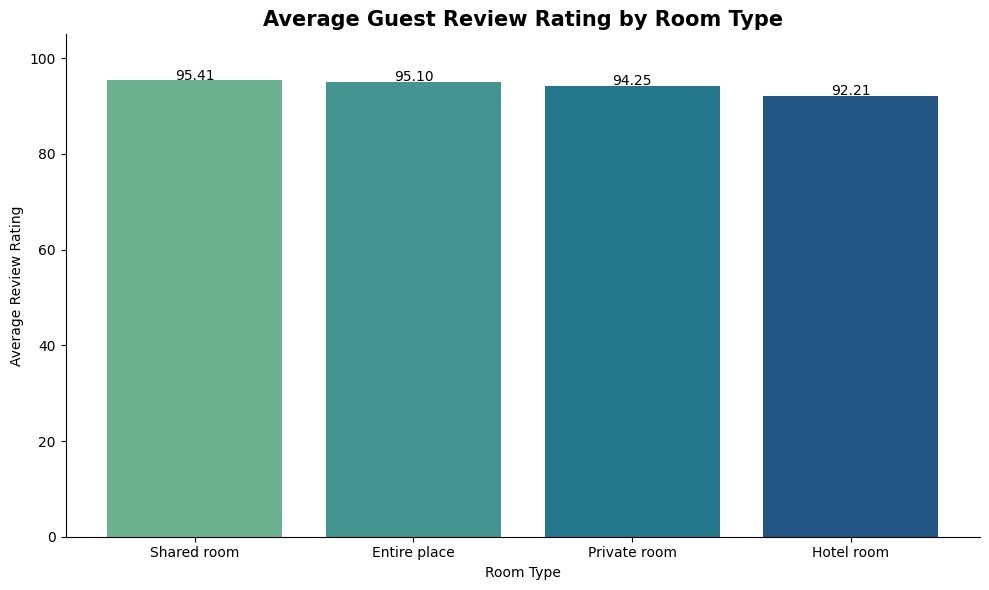

In [0]:
 # Import pandas for the numeric conversion
import pandas as pd

# Keep only records with available room types
rating_data = listing[listing["room_type"] != "null"].copy()

# Convert the text review ratings into numeric values
rating_data["review_scores_rating"] = pd.to_numeric(
    rating_data["review_scores_rating"],
    errors="coerce"
)

# Remove listings without a valid review rating
rating_data = rating_data.dropna(subset=["review_scores_rating"])

# Calculate average ratings by room type
rating_summary = (
    rating_data.groupby("room_type")["review_scores_rating"]
    .mean()
    .sort_values(ascending=False)
)

# Create the bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    rating_summary.index,
    rating_summary.values,
    color=sns.color_palette("crest", len(rating_summary))
)

# Add title and labels
plt.title("Average Guest Review Rating by Room Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Room Type")
plt.ylabel("Average Review Rating")

# Add values above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{bar.get_height():.2f}",
        ha="center"
    )

# Ratings range from 0 to 100
plt.ylim(0, 105)

sns.despine()
plt.tight_layout()
plt.show()

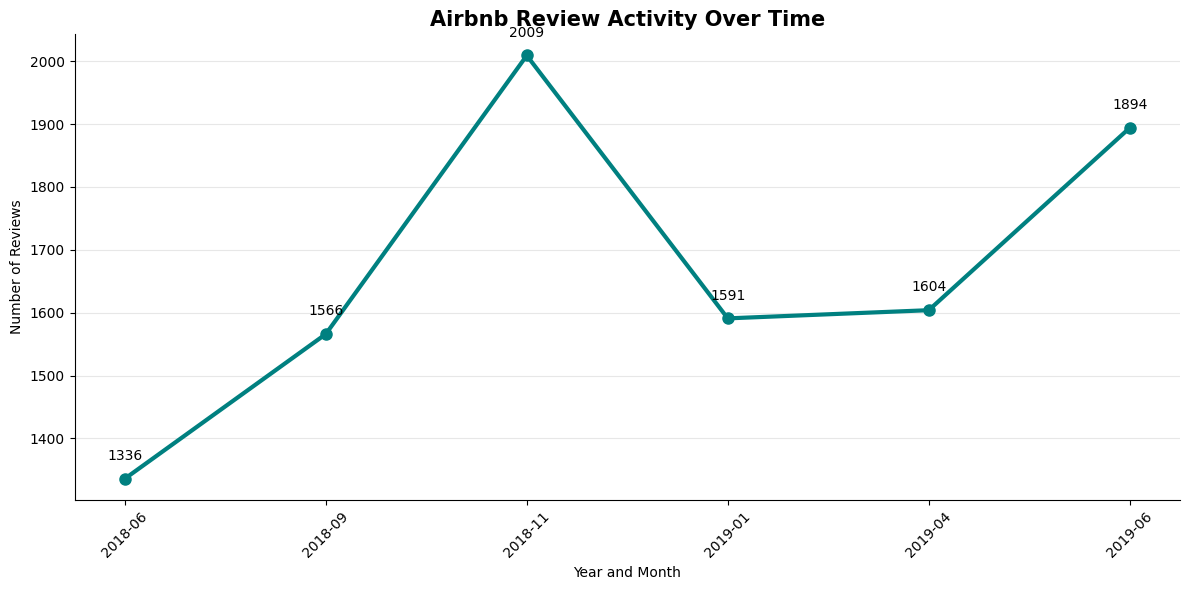

In [0]:
 # Extract year and month from the review date
reviews["year_month"] = reviews["date"].dt.to_period("M").astype(str)

# Count reviews for each month
monthly_reviews = (
    reviews.groupby("year_month")["review_id"]
    .count()
    .sort_index()
)

# Create the line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_reviews.index,
    monthly_reviews.values,
    marker="o",
    linewidth=3,
    markersize=8,
    color="teal"
)

# Add title and labels
plt.title("Airbnb Review Activity Over Time",
          fontsize=15, fontweight="bold")
plt.xlabel("Year and Month")
plt.ylabel("Number of Reviews")

# Display review counts
for x, y in zip(monthly_reviews.index, monthly_reviews.values):
    plt.text(x, y + 30, str(y), ha="center")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()

In [0]:
 # Import Pandas
import pandas as pd

# Group reviews by listing ID
# Count how many reviews belong to each listing
reviews_summary = (
    reviews.groupby("listing_id")
    .agg(
        total_reviews=("review_id", "count"),
        first_review=("date", "min"),
        latest_review=("date", "max")
    )
    .reset_index()
)

# Display the first 10 rows
display(reviews_summary.head(10))

# Check the number of unique listings in the review summary
print("Unique listings in review summary:", len(reviews_summary))

# Check whether listing IDs are duplicated
print("Duplicate listing IDs:", reviews_summary["listing_id"].duplicated().sum())

listing_id,total_reviews,first_review,latest_review
11170,2,2019-01-01T00:00:00.000Z,2019-04-22T00:00:00.000Z
11213,1,2018-11-04T00:00:00.000Z,2018-11-04T00:00:00.000Z
11798,1,2018-09-30T00:00:00.000Z,2018-09-30T00:00:00.000Z
11848,2,2018-11-04T00:00:00.000Z,2019-06-02T00:00:00.000Z
12452,1,2019-01-01T00:00:00.000Z,2019-01-01T00:00:00.000Z
15383,1,2018-09-30T00:00:00.000Z,2018-09-30T00:00:00.000Z
16455,1,2018-09-30T00:00:00.000Z,2018-09-30T00:00:00.000Z
17919,2,2018-09-30T00:00:00.000Z,2019-06-02T00:00:00.000Z
19306,1,2018-11-04T00:00:00.000Z,2018-11-04T00:00:00.000Z
22979,1,2018-06-03T00:00:00.000Z,2018-06-03T00:00:00.000Z


Unique listings in review summary: 7084
Duplicate listing IDs: 0
